<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/DEHOAQNN_IoTIntrusion_Mohammad2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DEHOA-optimised deep intrusion detection with a quantum neural network extension: Mohammad & Mohammad (2026) step by step

This notebook re-implements, runs and checks the experiments of

> A. Mohammad and H. Mohammad, "DEHOA-optimized deep intrusion detection with quantum neural network extensions for IoT network security," *Array* **31**, 101085 (2026). https://doi.org/10.1016/j.array.2026.101085

**What the paper does.** It proposes **DEHOA**, a metaheuristic that pairs *Double Exponential Smoothing* (DES, a trend forecaster) with the *Hippopotamus Optimisation Algorithm* (HOA, a swarm search), and uses it to tune every trainable part of a three-stage network intrusion detector for the **NSL-KDD** benchmark: (1) Min-Max scaling and SMOTE oversampling, (2) a *Morisita Overlap Index* (MOI) feature ranking that keeps 8 of the 41 features, which feed a recurrent network (RNN) whose learning rate is found by DEHOA and whose 32-dimensional penultimate layer is the learned representation, and (3) a multilayer perceptron (MLP) whose learning rate, two hidden sizes and dropout are found by DEHOA. A **variational quantum circuit (VQC)**, the "DEHOA-QNN", replaces the MLP as an optional quantum back end: 4 qubits, angle encoding, 4 variational layers and a circular CNOT ring, with its 16 parameters also found by DEHOA (no gradients). The paper reports 76.3 % accuracy and F1 = 0.732 on NSL-KDD, an ablation (Table 2), comparisons with LSTM, BTAD and QSVM-IGWO (Tables 3-4), an optimiser comparison (Table 6) and F1 = 0.974 on UNSW-NB15 (Table 7).

**What this notebook does.**
1. downloads NSL-KDD (`KDDTrain+`, `KDDTest+`) and the UNSW-NB15 official partitions from public mirrors and shows the real data (class counts, labelled 2-D projections);
2. implements the pipeline: Min-Max scaling, SMOTE, MOI ranking, **DEHOA written from the paper's Eqs. (3)-(5)**, DEHOA-RNN embedding, DEHOA-MLP classifier, the **PennyLane VQC** with 16 parameters trained by DEHOA, and draws the executed circuit;
3. trains the classical baselines the paper names (MLP without DEHOA, LSTM) plus a random forest and an RBF SVM on identical inputs, reruns the ablation (Table 2), an optimiser comparison (Table 6) and the UNSW-NB15 cross-dataset run (Table 7), including the leakage-prone protocol the paper describes;
4. repeats the pipeline over several seeds and prints a claim-by-claim comparison with the paper.

**How to run it.** Open it in Colab (badge above), choose a **CPU** runtime and use *Runtime -> Run all*. No GPU, no IBM account and no Hugging Face token are needed (both datasets come from public mirrors). With `FAST_MODE = True` (about 10 minutes) the DEHOA budgets are tiny, so the numbers are indicative only; `FAST_MODE = False` uses the paper's budgets (8 agents x 12 iterations for the RNN, 15 x 25 for the MLP, 15 x 40 for the VQC) and took 64 minutes on a shared 4-core laptop CPU (3 seeds).

**Hugging Face token.** The UNSW-NB15 mirror used here is public. If you swap in a gated Hugging Face dataset, add your own token as a Colab Secret named `HF_TOKEN` (key icon, left panel); locally set the environment variable `HF_TOKEN`. The notebook only reads it from there and never prints it.

**What you get at the end.** A table of the paper's numbers next to this notebook's, with a verdict per claim ("reproduced" within 2 accuracy points or 0.02 F1, "not reached", "exceeded" or "cannot be checked"), the circuit drawing, and a critical reading of the paper.

## The paper in one page

| Item | What the paper says |
|---|---|
| Problem | Multi-class intrusion detection on IoT-style traffic: Normal, DoS, Probing, U2R, R2L (NSL-KDD). |
| Data | NSL-KDD: `KDDTrain+` (125,973 records) and `KDDTest+` (22,544), 41 features, used without modification; UNSW-NB15 (10 classes) for cross-dataset checking. |
| Stage 1 | Label-encode `protocol_type`, `service`, `flag`; Min-Max scaling fitted on the training split (Eq. 1); SMOTE on the training split only. |
| Stage 2 | MOI (Eq. 2) ranks the features by how little the Normal and attack histograms overlap; the 8 lowest-overlap features feed an RNN (64 tanh units, single-step sequence) whose 32-unit penultimate layer is the embedding. DEHOA tunes the RNN learning rate in [1e-5, 5e-2]: 8 agents, 12 iterations, fitness = validation cross-entropy after 5 warm-up epochs on a 5,000-sample subsample; final RNN up to 20 epochs with early stopping. |
| Stage 3 | MLP (two ReLU layers, BatchNorm, Dropout) on the 32-d embedding. DEHOA tunes {log lr, h1, h2, dropout}: 15 agents, 25 iterations, 10 epochs on 8,000 samples per evaluation; final MLP 50 epochs with early stopping. |
| DEHOA | DES level/trend `L_t`, `T_t` of the best fitness (Eqs. 3-4), forecast `F = L_t + T_t`, position update `X_i <- X_i + r1 (X_best - X_i) + r2 F eps` (Eq. 5), plus the three HOA behaviours (dominance, territorial defence, obstacle avoidance). |
| Quantum extension | 4 qubits, `R_y(f_i pi)` angle encoding, 4 variational layers of `R_y` + circular CNOT, Pauli-Z read-out, a Dense layer to 5 classes; 16 parameters tuned by DEHOA (15 agents, 40 iterations), statevector simulator. |
| Claims | NSL-KDD accuracy 0.763, F1 0.732, AUC 0.891 (Table 3); per-class recall Normal 97.4 %, DoS 76.3 %, Probe 66.1 %, U2R 9.0 %, R2L 9.9 % (Sec. 4.2); ablation F1 0.669 / 0.738 / 0.724 / 0.730 / 0.722 (Table 2); LSTM 0.728, BTAD 0.732, MLP 0.740, QSVM-IGWO 0.759 (Table 3); Wilcoxon equivalence with LSTM/BTAD/MLP (Table 4); optimisers equivalent except TPE (Table 6); UNSW-NB15 accuracy 0.969, F1 0.974 (Table 7); the QNN is "lower" than the others (Fig. 9, no numbers in the text). |

## What follows the paper and what had to be chosen

The paper gives no code ("available on reasonable request") and leaves many details open. Every choice below is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Datasets | NSL-KDD (main), UNSW-NB15 (Table 7); the index of the project also lists KDD99, CIC-IDS2017, Bot-IoT, Elliptic, but the experiments only use these two (the others appear in "future work") | NSL-KDD `KDDTrain+`/`KDDTest+` (GitHub mirror `defcom17/NSL_KDD`) and UNSW-NB15 official train/test partitions (Hugging Face mirror `research-simulation26/unsw-nb15-parquet`, 41 features; the paper says 49 features and 562,980 records, which does not match the public partitions of 257,673 records) |
| Neural-network code | TensorFlow 2.x | The MLP and the single-step RNN are written in **NumPy** (manual back-propagation, Adam, BatchNorm, Dropout). A single-step `SimpleRNN` is exactly a Dense tanh layer (the recurrent kernel multiplies a zero state), a cell checks this against Keras. Reason: DEHOA needs hundreds of cheap network trainings and Keras' per-model overhead was 5-10 times slower on a CPU. The LSTM baseline uses Keras. |
| Training set size | all 125,973 records, SMOTE to the majority size | `CAP_PER_CLASS` records per class kept before SMOTE (smaller classes kept whole), so SMOTE balances every class to the cap |
| Validation data | not described | 15 % of the real training records held out (stratified) before capping/SMOTE; at most `VAL_N` of them used for fitness and early stopping |
| MOI histograms | number of bins not stated | 20 equal-width bins on the Min-Max scale, Normal vs. all attacks, computed on the real training part; Eq. (2) is evaluated on bin *proportions* (Morisita-Horn form), because with raw counts the unequal class sizes would dominate |
| RNN | 64 tanh units, 32-unit penultimate layer | single-step input, `Dense(64, tanh) -> Dense(32, tanh) -> softmax`, batch 128 |
| MLP | two ReLU layers, BN, Dropout, Adam | `Dense(h1)-ReLU-BN-Dropout-Dense(h2)-ReLU-BN-Dropout-softmax`, batch 256 (not stated), Adam |
| Search bounds | RNN lr in [1e-5, 5e-2]; MLP bounds not stated | MLP: log10 lr in [-4, -1.5], h1 in [16, 128], h2 in [8, 64], dropout in [0, 0.5] |
| HOA phases | described in words (dominance, territorial defence, obstacle avoidance), only Eq. (5) given | each agent picks one phase per iteration: dominance `X + r1 (X_best - I X)` (I in {1, 2}), territorial defence `X + 0.5 r3 (X - P)` with a random predator `P`, local escape with a radius shrinking over the iterations; Eq. (5)'s `r2 F eps` term is added to every move; reflection at the bounds; greedy replacement |
| DES constants | not stated | `alpha = 0.5`, `beta = 0.3`, noise `eps ~ N(0, 0.1)` in the unit cube; the DES series is the best fitness found so far; `F` below 0 is clipped to 0 |
| Evaluation budget | N x iterations (e.g. 15 x 25 = 375) | the initial population counts as iteration 1, so the budget is exactly N x iterations |
| VQC circuit | text says "Rx, Ry, Rz" per layer in one place and "16 variational parameters" and "Ry rotations" in another | the 16-parameter reading: one `R_y` per qubit per layer, circular CNOT ring |
| 32-d embedding -> 4 qubits | not stated | PCA(4) fitted on the training embedding, Min-Max to [0, 1], `R_y(f pi)` |
| Dense read-out of the VQC | trained how is not stated | 4 Pauli-Z expectations -> softmax regression refitted inside every fitness call (so DEHOA searches the 16 circuit parameters only) |
| Seeds / runs | 10 independent runs | `N_RUNS` seeds (FAST_MODE: 2, full run: 3); the Wilcoxon tests are only computed when enough paired runs exist |
| Statistical tests, Optuna TPE, BTAD, QSVM-IGWO | reported | BTAD and QSVM-IGWO are not re-implemented (their numbers are quoted); the TPE row is skipped (Optuna is not installed); HOA-only, random search and grid search are run at a reduced matched budget |

In [1]:
# Install (pinned to the versions this notebook was tested with). Colab already ships numpy, pandas, scikit-learn,
# matplotlib and tensorflow; a runtime restart may be asked for after the install.
import sys, importlib, subprocess
IN_COLAB = "google.colab" in sys.modules

def _missing():
    for mod in ("pennylane", "imblearn", "tensorflow", "huggingface_hub", "pyarrow"):
        try:
            importlib.import_module(mod)
        except Exception:
            return True
    return False

if IN_COLAB or _missing():
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "imbalanced-learn==0.14.2",
                    "pyarrow", "huggingface_hub"], check=False)
print("install cell done (Colab: %s)" % IN_COLAB)

install cell done (Colab: False)


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False           # True: tiny DEHOA budgets, a class demo in about 10 minutes. False: the paper's budgets (about an hour).
SEED      = 42              # CHOICE: the paper only says "different random seeds"
IBM_TOKEN = ""              # not used: the paper simulates the circuit on a statevector simulator

DATA_DIR = "data"           # downloaded files are cached here
LOCAL_NSL_DIR  = None       # optional: folder that already holds KDDTrain+.txt and KDDTest+.txt
LOCAL_UNSW_DIR = None       # optional: folder that holds training_set.parquet and testing_set.parquet

VAL_FRACTION = 0.15         # CHOICE: share of the real training records held out for fitness / early stopping
NSL_CLASSES  = ["Normal", "DoS", "Probe", "U2R", "R2L"]   # paper order: Normal 0, DoS 1, Probing 2, U2R 3, R2L 4
MOI_BINS     = 20           # CHOICE: histogram bins of the Morisita overlap
N_MOI        = 8            # paper: top-8 features
EMB_DIM      = 32           # paper: 32-d embedding
DES_ALPHA, DES_BETA, DES_SIGMA = 0.5, 0.3, 0.1   # CHOICE: DES smoothing constants and noise level (unit-cube scale)
RNN_LR_BOUNDS = (1e-5, 5e-2)                      # paper
MLP_BOUNDS = {"log_lr": (-4.0, -1.5), "h1": (16, 128), "h2": (8, 64), "dropout": (0.0, 0.5)}   # CHOICE (paper gives none)
QNN_QUBITS, QNN_LAYERS = 4, 4                     # paper: 4 qubits, 4 variational layers -> 16 parameters

if FAST_MODE:
    CAP_PER_CLASS = 1500; VAL_N = 3000
    RNN_AGENTS, RNN_ITERS, RNN_FIT_N, RNN_WARM = 4, 4, 2000, 3             # paper: 8, 12, 5000, 5
    MLP_AGENTS, MLP_ITERS, MLP_FIT_N, MLP_FIT_EPOCHS = 5, 5, 3000, 4       # paper: 15, 25, 8000, 10
    QNN_AGENTS, QNN_ITERS, QNN_FIT_N, QNN_VAL_N = 8, 10, 600, 600          # paper: 15, 40
    FINAL_RNN_EPOCHS, FINAL_MLP_EPOCHS, DEFAULT_MLP_EPOCHS = 10, 20, 15    # paper: 20, 50
    N_RUNS = 2
    LSTM_EPOCHS, LSTM_TRAIN_N = 3, 6000
    SVC_N = 3000
    OPT_LEVELS, OPT_REPS, OPT_FIT_N, OPT_EPOCHS = 2, 2, 2000, 3            # grid levels per dimension -> budget = levels^4
    UNSW_CAP = 800; UNSW_RNN = (4, 4); UNSW_MLP = (4, 4)
else:
    CAP_PER_CLASS = 12000; VAL_N = 8000
    RNN_AGENTS, RNN_ITERS, RNN_FIT_N, RNN_WARM = 8, 12, 5000, 5
    MLP_AGENTS, MLP_ITERS, MLP_FIT_N, MLP_FIT_EPOCHS = 15, 25, 8000, 10
    QNN_AGENTS, QNN_ITERS, QNN_FIT_N, QNN_VAL_N = 15, 40, 1500, 1500
    FINAL_RNN_EPOCHS, FINAL_MLP_EPOCHS, DEFAULT_MLP_EPOCHS = 20, 50, 30
    N_RUNS = 3
    LSTM_EPOCHS, LSTM_TRAIN_N = 6, 30000
    SVC_N = 8000
    OPT_LEVELS, OPT_REPS, OPT_FIT_N, OPT_EPOCHS = 3, 2, 3000, 5
    UNSW_CAP = 5000; UNSW_RNN = (8, 12); UNSW_MLP = (8, 10)
RUN_SEEDS = [SEED + i for i in range(N_RUNS)]
print("FAST_MODE =", FAST_MODE, "| seeds:", RUN_SEEDS)
print("budgets  RNN %dx%d  MLP %dx%d  QNN %dx%d" % (RNN_AGENTS, RNN_ITERS, MLP_AGENTS, MLP_ITERS, QNN_AGENTS, QNN_ITERS))

FAST_MODE = False | seeds: [42, 43, 44]
budgets  RNN 8x12  MLP 15x25  QNN 15x40


In [3]:
import os, time, warnings, math, copy, io
warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score, confusion_matrix,
                             roc_auc_score, roc_curve, log_loss)
from scipy import stats
from imblearn.over_sampling import SMOTE
import pennylane as qml

rng = np.random.default_rng(SEED)
np.random.seed(SEED)
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    tf.random.set_seed(SEED); keras.utils.set_random_seed(SEED)
    try:
        tf.config.threading.set_intra_op_parallelism_threads(2); tf.config.threading.set_inter_op_parallelism_threads(1)
    except Exception:
        pass
    TF_VERSION = tf.__version__
except Exception as e:      # the LSTM baseline and the Keras equivalence check are skipped without TensorFlow
    tf = keras = layers = None; TF_VERSION = "not available (%s)" % type(e).__name__
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
CLASS_COLORS = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860", "#DA8BC3", "#8C8C8C", "#CCB974", "#64B5CD"]
print("numpy", np.__version__, "| pandas", pd.__version__, "| PennyLane", qml.__version__, "| TensorFlow", TF_VERSION)

numpy 2.5.4 | pandas 3.0.6 | PennyLane 0.45.1 | TensorFlow 2.21.0


## 1. Data: NSL-KDD and UNSW-NB15

NSL-KDD is the cleaned successor of KDD Cup 1999: 41 features per connection (3 categorical: `protocol_type`, `service`, `flag`) and 38 attack names that group into four families (DoS, Probe, U2R, R2L). `KDDTest+` also contains attack names that never occur in `KDDTrain+`, so it tests generalisation to new variants. The class map below follows the standard NSL-KDD grouping (the same one used by the other notebooks of this repository).

UNSW-NB15 is only used for the paper's cross-dataset check (Table 7). Both datasets are downloaded from public mirrors and cached in `DATA_DIR`.

In [4]:
NSL_COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
    "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count", "srv_count",
    "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate",
    "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "label", "difficulty"]
NSL_CAT = ["protocol_type", "service", "flag"]
NSL_FEATURES = [c for c in NSL_COLUMNS if c not in ("label", "difficulty")]
FAMILY = {"normal": "Normal"}
for a in ["back", "land", "neptune", "pod", "smurf", "teardrop", "apache2", "udpstorm", "processtable", "worm", "mailbomb"]: FAMILY[a] = "DoS"
for a in ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]: FAMILY[a] = "Probe"
for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster", "warezclient", "spy", "xlock", "xsnoop",
          "snmpguess", "snmpgetattack", "httptunnel", "sendmail", "named"]: FAMILY[a] = "R2L"
for a in ["buffer_overflow", "loadmodule", "rootkit", "perl", "sqlattack", "xterm", "ps"]: FAMILY[a] = "U2R"

NSL_URLS = {"KDDTrain+.txt": ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
                              "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"],
            "KDDTest+.txt":  ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt",
                              "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest%2B.txt"]}

def fetch_nsl(name):
    folder = LOCAL_NSL_DIR or DATA_DIR
    path = os.path.join(folder, name)
    if not os.path.exists(path):
        import requests
        for url in NSL_URLS[name]:
            try:
                r = requests.get(url, timeout=120); r.raise_for_status()
                open(path, "wb").write(r.content); print("downloaded", name, "from", url.split("/")[3]); break
            except Exception as e:
                print("failed:", url, type(e).__name__)
        else:
            raise RuntimeError("could not download " + name + "; put it in DATA_DIR or set LOCAL_NSL_DIR")
    return pd.read_csv(path, header=None, names=NSL_COLUMNS)

t0 = time.time()
nsl_tr_raw, nsl_te_raw = fetch_nsl("KDDTrain+.txt"), fetch_nsl("KDDTest+.txt")
for df in (nsl_tr_raw, nsl_te_raw):
    df["family"] = df["label"].map(FAMILY)
    assert df["family"].notna().all(), sorted(set(df.loc[df["family"].isna(), "label"]))
print("NSL-KDD loaded in %.1f s: KDDTrain+ %s (paper 125,973), KDDTest+ %s (paper 22,544)" % (time.time() - t0, nsl_tr_raw.shape, nsl_te_raw.shape))

# ---- UNSW-NB15 (official training / testing partitions)
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
UNSW_REPO, UNSW_ALT = "research-simulation26/unsw-nb15-parquet", "Mireu-Lab/UNSW-NB15"

def tidy_unsw(df):
    df = df.copy(); df.columns = [c.strip().lower() for c in df.columns]
    df = df.drop(columns=["id", "label"], errors="ignore")
    df["attack_cat"] = df["attack_cat"].astype(str).str.strip().replace({"Backdoors": "Backdoor", "": "Normal", "-": "Normal", "nan": "Normal"})
    for c in ("proto", "service", "state"):
        df[c] = df[c].astype(str).str.strip()
    return df

def load_unsw():
    rd = lambda p: pd.read_parquet(p) if str(p).endswith(".parquet") else pd.read_csv(p, low_memory=False)
    if LOCAL_UNSW_DIR:
        return (tidy_unsw(rd(os.path.join(LOCAL_UNSW_DIR, "training_set.parquet"))), tidy_unsw(rd(os.path.join(LOCAL_UNSW_DIR, "testing_set.parquet"))))
    from huggingface_hub import hf_hub_download
    try:
        d = os.path.join(DATA_DIR, "unsw_main")
        tr = hf_hub_download(UNSW_REPO, "training_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        te = hf_hub_download(UNSW_REPO, "testing_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        return tidy_unsw(rd(tr)), tidy_unsw(rd(te))
    except Exception as e:
        print("primary mirror failed (%s) -> fallback %s (its file names are swapped)" % (type(e).__name__, UNSW_ALT))
        d = os.path.join(DATA_DIR, "unsw_alt")
        a = hf_hub_download(UNSW_ALT, "test.csv", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        b = hf_hub_download(UNSW_ALT, "train.csv", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        return tidy_unsw(rd(a)), tidy_unsw(rd(b))

t0 = time.time()
unsw_tr_raw, unsw_te_raw = load_unsw()
assert len(unsw_tr_raw) > len(unsw_te_raw), "partitions look swapped"
print("UNSW-NB15 loaded in %.1f s: training %s, testing %s (paper: 562,980 records, 49 features)" % (time.time() - t0, unsw_tr_raw.shape, unsw_te_raw.shape))

NSL-KDD loaded in 3.0 s: KDDTrain+ (125973, 44) (paper 125,973), KDDTest+ (22544, 44) (paper 22,544)


UNSW-NB15 loaded in 2.7 s: training (175341, 43), testing (82332, 43) (paper: 562,980 records, 49 features)


In [5]:
class Bundle:
    # One dataset in numeric form: label-encoded categoricals, Min-Max scaled (fitted on the training records only).
    pass

def make_bundle(name, tr, te, feat_cols, cat_cols, label_col, class_names, raw_label_col=None):
    B = Bundle(); B.name = name; B.class_names = list(class_names); B.feat_names = list(feat_cols); B.n_classes = len(class_names)
    Xtr, Xte = tr[feat_cols].copy(), te[feat_cols].copy()
    B.cat_maps = {}
    for c in cat_cols:                           # CHOICE: the category vocabulary of train+test is label-encoded (no statistics, no labels used)
        cats = sorted(set(Xtr[c]).union(set(Xte[c]))); B.cat_maps[c] = {k: i for i, k in enumerate(cats)}
        Xtr[c] = Xtr[c].map(B.cat_maps[c]); Xte[c] = Xte[c].map(B.cat_maps[c])
    B.Xtr_raw, B.Xte_raw = Xtr.to_numpy(np.float32), Xte.to_numpy(np.float32)
    cmap = {c: i for i, c in enumerate(class_names)}
    B.ytr, B.yte = tr[label_col].map(cmap).to_numpy(), te[label_col].map(cmap).to_numpy()
    assert not np.isnan(B.ytr.astype(float)).any() and not np.isnan(B.yte.astype(float)).any()
    B.ytr, B.yte = B.ytr.astype(int), B.yte.astype(int)
    B.raw_label_tr = tr[raw_label_col or label_col].to_numpy(); B.raw_label_te = te[raw_label_col or label_col].to_numpy()
    B.scaler = MinMaxScaler().fit(B.Xtr_raw)               # Eq. (1), fitted on the training records only
    B.Xtr = B.scaler.transform(B.Xtr_raw).astype(np.float32)
    B.Xte = np.clip(B.scaler.transform(B.Xte_raw), 0, 1).astype(np.float32)   # test values outside the training range are clipped
    return B

NSL = make_bundle("NSL-KDD", nsl_tr_raw, nsl_te_raw, NSL_FEATURES, NSL_CAT, "family", NSL_CLASSES, raw_label_col="label")

unsw_feats = [c for c in unsw_tr_raw.columns if c != "attack_cat"]
unsw_order = ["Normal"] + [c for c in unsw_tr_raw["attack_cat"].value_counts().index if c != "Normal"]
UNSW = make_bundle("UNSW-NB15", unsw_tr_raw, unsw_te_raw, unsw_feats, ["proto", "service", "state"], "attack_cat", unsw_order)
for B in (NSL, UNSW):
    print("%-10s train %s test %s | %d classes | scaled range of train [%.2f, %.2f]" % (B.name, B.Xtr.shape, B.Xte.shape, B.n_classes, B.Xtr.min(), B.Xtr.max()))

NSL-KDD    train (125973, 41) test (22544, 41) | 5 classes | scaled range of train [0.00, 1.00]
UNSW-NB15  train (175341, 42) test (82332, 42) | 10 classes | scaled range of train [0.00, 1.00]


## Dataset Exploration and Visualisation

Before any modelling, look at the real records. For each dataset: shape, feature names, the original labels with their counts, the real class distribution, and a 2-D scatter of real observations coloured by their ground-truth class. The PCA is **fitted on a sample of the training records only** and the test records are projected with it. NSL-KDD points are coloured by attack *family* (the label the paper classifies); the raw attack names are listed in the counts.

NSL-KDD
train (125973, 41) | test (22544, 41) | 41 features
features: duration, protocol_type, service, flag, src_bytes, dst_bytes, land, wrong_fragment, urgent, hot, num_failed_logins, logged_in, num_compromised, root_shell, su_attempted, num_root, num_file_creations, num_shells, num_access_files, num_outbound_cmds, is_host_login, is_guest_login, count, srv_count, serror_rate, srv_serror_rate, rerror_rate, srv_rerror_rate, same_srv_rate, diff_srv_rate, srv_diff_host_rate, dst_host_count, dst_host_srv_count, dst_host_same_srv_rate, dst_host_diff_srv_rate, dst_host_same_src_port_rate, dst_host_srv_diff_host_rate, dst_host_serror_rate, dst_host_srv_serror_rate, dst_host_rerror_rate, dst_host_srv_rerror_rate
categorical (label-encoded): {'protocol_type': 3, 'service': 70, 'flag': 11}
original label values (40 distinct), most frequent first:


,train,test
label,,
normal,67343,9711
neptune,41214,4657
satan,3633,735
ipsweep,3599,141
portsweep,2931,157
smurf,2646,665
nmap,1493,73
back,956,359
teardrop,892,12


class counts used for classification:


,train,test,train %,test %
Normal,67343,9711,53.46,43.08
DoS,45927,7460,36.46,33.09
Probe,11656,2421,9.25,10.74
U2R,52,67,0.04,0.30
R2L,995,2885,0.79,12.80


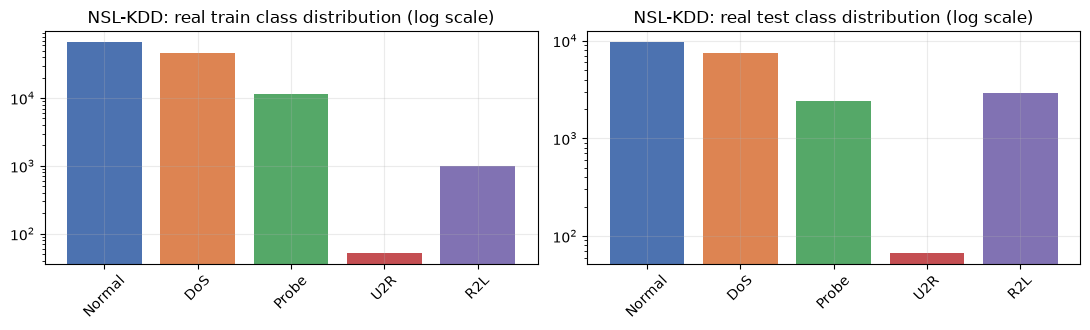

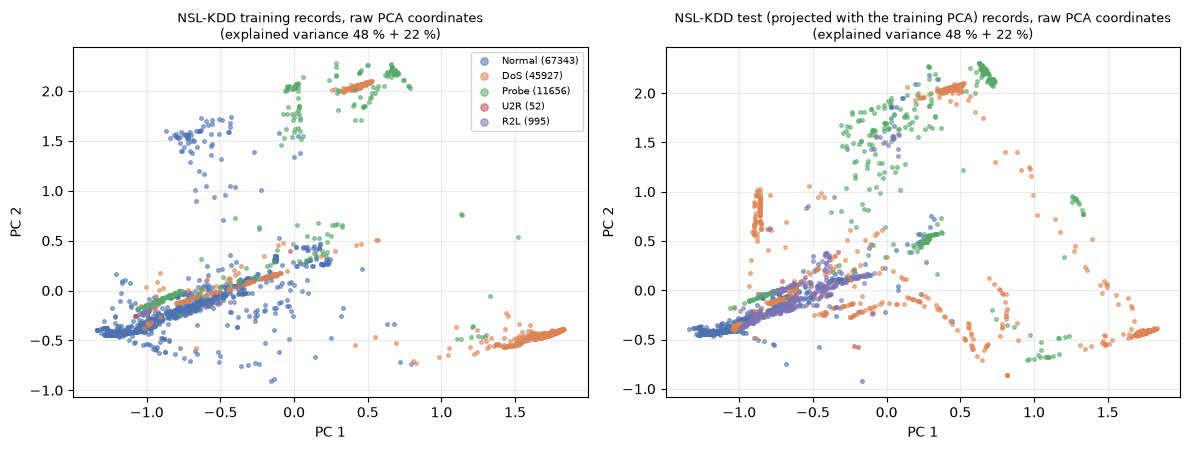

In [6]:
def show_dataset(B, tr_raw, te_raw, name_col, top=12):
    print("=" * 100); print(B.name)
    print("train", B.Xtr_raw.shape, "| test", B.Xte_raw.shape, "| %d features" % len(B.feat_names))
    print("features:", ", ".join(B.feat_names))
    print("categorical (label-encoded):", {c: len(m) for c, m in B.cat_maps.items()})
    vc = pd.concat([tr_raw[name_col].value_counts().rename("train"), te_raw[name_col].value_counts().rename("test")], axis=1).fillna(0).astype(int)
    print("original label values (%d distinct), most frequent first:" % len(vc)); display(vc.sort_values("train", ascending=False).head(top))
    cc = pd.DataFrame({"train": np.bincount(B.ytr, minlength=B.n_classes), "test": np.bincount(B.yte, minlength=B.n_classes)}, index=B.class_names)
    cc["train %"] = (100 * cc["train"] / cc["train"].sum()).round(2); cc["test %"] = (100 * cc["test"] / cc["test"].sum()).round(2)
    print("class counts used for classification:"); display(cc)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
    for a, (split, y) in zip(ax, (("train", B.ytr), ("test", B.yte))):
        a.bar(B.class_names, np.bincount(y, minlength=B.n_classes), color=CLASS_COLORS[:B.n_classes]); a.set_yscale("log")
        a.set_title("%s: real %s class distribution (log scale)" % (B.name, split)); a.tick_params(axis="x", rotation=45)
    plt.tight_layout(); plt.show()

def scatter_real(B, n_fit=8000, n_show=3000, seed=SEED):
    # PCA fitted on a sample of the TRAINING records only; coordinates of real train and test records, coloured by ground truth
    r = np.random.default_rng(seed)
    fit_idx = r.choice(len(B.Xtr), min(n_fit, len(B.Xtr)), replace=False)
    pca = PCA(n_components=2, random_state=SEED).fit(B.Xtr[fit_idx])
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
    for a, (split, X, y) in zip(ax, (("training", B.Xtr, B.ytr), ("test (projected with the training PCA)", B.Xte, B.yte))):
        idx = r.choice(len(X), min(n_show, len(X)), replace=False); Z = pca.transform(X[idx])
        for c in range(B.n_classes):
            m = y[idx] == c
            a.scatter(Z[m, 0], Z[m, 1], s=7, alpha=0.55, color=CLASS_COLORS[c], label="%s (%d)" % (B.class_names[c], (y == c).sum()))
        a.set_title("%s %s records, raw PCA coordinates\n(explained variance %.0f %% + %.0f %%)" % (B.name, split, 100 * pca.explained_variance_ratio_[0], 100 * pca.explained_variance_ratio_[1]), fontsize=9)
        a.set_xlabel("PC 1"); a.set_ylabel("PC 2")
    ax[0].legend(markerscale=2, fontsize=7, loc="best"); plt.tight_layout(); plt.show()

show_dataset(NSL, nsl_tr_raw, nsl_te_raw, "label")
scatter_real(NSL)

UNSW-NB15
train (175341, 42) | test (82332, 42) | 42 features
features: dur, proto, service, state, spkts, dpkts, sbytes, dbytes, rate, sttl, dttl, sload, dload, sloss, dloss, sintpkt, dintpkt, sjit, djit, swin, stcpb, dtcpb, dwin, tcprtt, synack, ackdat, smeansz, dmeansz, trans_depth, res_bdy_len, ct_srv_src, ct_state_ttl, ct_dst_ltm, ct_src_dport_ltm, ct_dst_sport_ltm, ct_dst_src_ltm, is_ftp_login, ct_ftp_cmd, ct_flw_http_mthd, ct_src_ltm, ct_srv_dst, is_sm_ips_ports
categorical (label-encoded): {'proto': 133, 'service': 13, 'state': 11}
original label values (10 distinct), most frequent first:


,train,test
attack_cat,,
Normal,56000,37000
Generic,40000,18871
Exploits,33393,11132
Fuzzers,18184,6062
DoS,12264,4089
Reconnaissance,10491,3496
Analysis,2000,677
Backdoor,1746,583
Shellcode,1133,378


class counts used for classification:


,train,test,train %,test %
Normal,56000,37000,31.94,44.94
Generic,40000,18871,22.81,22.92
Exploits,33393,11132,19.04,13.52
Fuzzers,18184,6062,10.37,7.36
DoS,12264,4089,6.99,4.97
Reconnaissance,10491,3496,5.98,4.25
Analysis,2000,677,1.14,0.82
Backdoor,1746,583,1.00,0.71
Shellcode,1133,378,0.65,0.46
Worms,130,44,0.07,0.05


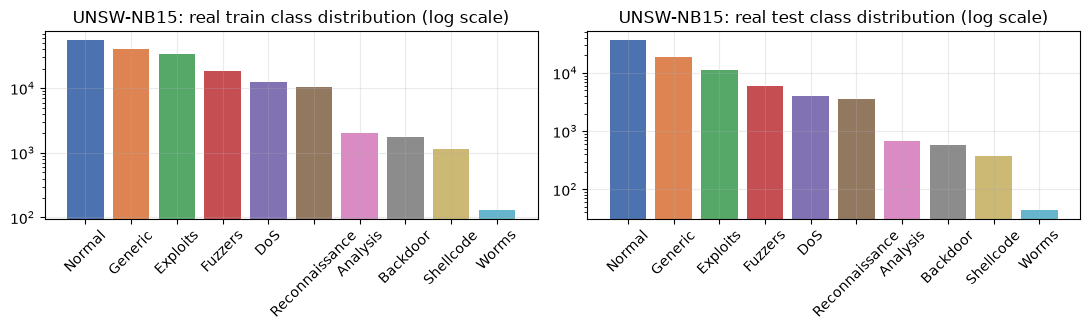

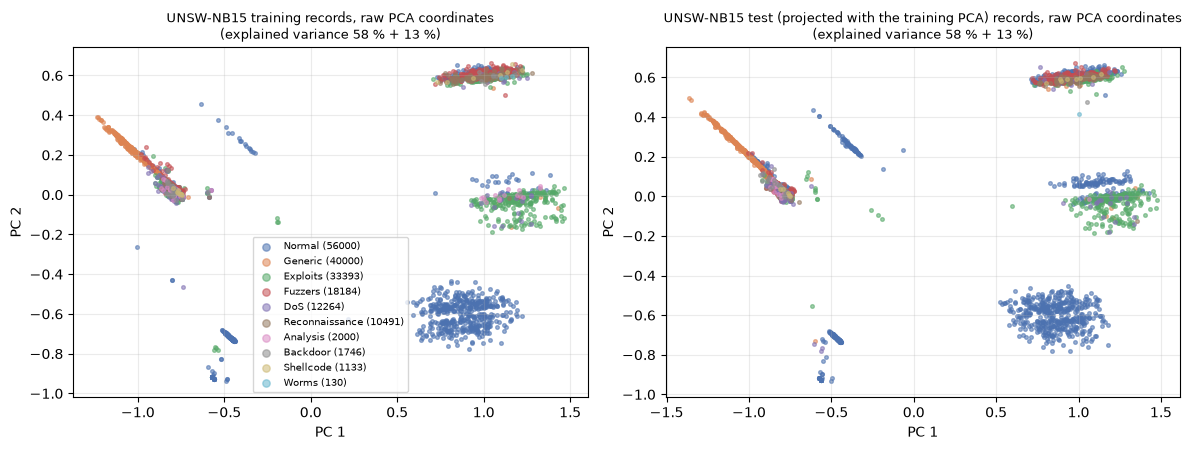

In [7]:
show_dataset(UNSW, unsw_tr_raw, unsw_te_raw, "attack_cat", top=10)
scatter_real(UNSW)

## 2. Preprocessing: Min-Max, SMOTE and Morisita feature ranking

Stage 1 of the paper. The Min-Max scaler was already fitted on the training records (Eq. 1). Now the training records are split into a *training part* and a *validation part* (real records only), the training part is capped per class and balanced with **SMOTE**, and the **Morisita Overlap Index** (Eq. 2) ranks the features.

The Morisita overlap of two histograms with proportions `p_i` and `q_i` is `C = 2 sum(p_i q_i) / (sum p_i^2 + sum q_i^2)`: 1 means identical histograms, 0 means no overlap. A feature whose Normal and attack histograms barely overlap is discriminative, so features are ranked by **ascending** overlap and the first 8 are kept. MOI is computed on the real training part (before SMOTE, so no synthetic record influences it).

real training part 107077 | capped real 34798 | after SMOTE 60000 | validation 8000 | test 22544
class counts  real(capped) -> SMOTE: {'Normal': (12000, 12000), 'DoS': (12000, 12000), 'Probe': (9908, 12000), 'U2R': (44, 12000), 'R2L': (846, 12000)}

MOI overlap (ascending), the first 8 are kept:


,feature,MOI,kept
0,service,0.191,True
1,dst_host_srv_count,0.194,True
2,dst_host_same_srv_rate,0.295,True
3,flag,0.298,True
4,diff_srv_rate,0.335,True
5,dst_host_diff_srv_rate,0.355,True
6,same_srv_rate,0.397,True
7,logged_in,0.400,True
8,count,0.473,False
9,dst_host_serror_rate,0.506,False


split + SMOTE + MOI: 2.2 s


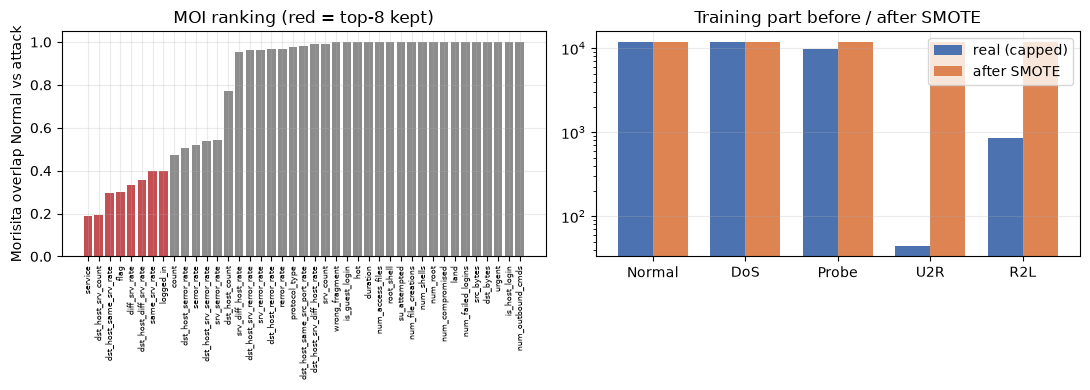

In [8]:
def moi_scores(X, is_attack, bins=MOI_BINS):
    # Morisita(-Horn) overlap between the Normal and attack histograms of every feature (X is on the [0, 1] scale)
    edges = np.linspace(0, 1, bins + 1); out = np.zeros(X.shape[1])
    for j in range(X.shape[1]):
        a, _ = np.histogram(X[~is_attack, j], bins=edges); b, _ = np.histogram(X[is_attack, j], bins=edges)
        p, q = a / max(a.sum(), 1), b / max(b.sum(), 1)
        out[j] = 2 * (p * q).sum() / ((p ** 2).sum() + (q ** 2).sum() + 1e-12)
    return out

def make_split(B, seed, cap=CAP_PER_CLASS, val_n=VAL_N):
    # Real train -> (training part, validation part); cap + SMOTE on the training part only; MOI on its real records.
    r = np.random.default_rng(seed)
    idx = np.arange(len(B.ytr))
    tr_i, va_i = train_test_split(idx, test_size=VAL_FRACTION, stratify=B.ytr, random_state=seed)
    Xp, yp = B.Xtr[tr_i], B.ytr[tr_i]
    moi = moi_scores(Xp, yp != 0); sel = np.argsort(moi)[:N_MOI]
    keep = []
    for c in range(B.n_classes):                     # CHOICE: cap every class, keep small classes whole
        ids = np.where(yp == c)[0]
        keep.append(r.choice(ids, cap, replace=False) if len(ids) > cap else ids)
    keep = np.concatenate(keep); Xc, yc = Xp[keep], yp[keep]
    k = int(min(5, np.bincount(yc).min() - 1))
    Xs, ys = SMOTE(random_state=seed, k_neighbors=max(k, 1)).fit_resample(Xc, yc)      # SMOTE on the training part only
    vsel = r.choice(len(va_i), min(val_n, len(va_i)), replace=False)
    S = dict(seed=seed, sel=sel, moi=moi, Xc=Xc, yc=yc, Xs=Xs.astype(np.float32), ys=ys, Xv=B.Xtr[va_i][vsel], yv=B.ytr[va_i][vsel],
             Xt=B.Xte, yt=B.yte, n_classes=B.n_classes, class_names=B.class_names, feat_names=B.feat_names, n_real_train=len(yp))
    return S

def describe_split(S):
    print("real training part %d | capped real %d | after SMOTE %d | validation %d | test %d" % (S["n_real_train"], len(S["yc"]), len(S["ys"]), len(S["yv"]), len(S["yt"])))
    print("class counts  real(capped) -> SMOTE:", {c: (int(a), int(b)) for c, a, b in zip(S["class_names"], np.bincount(S["yc"], minlength=S["n_classes"]), np.bincount(S["ys"], minlength=S["n_classes"]))})

t0 = time.time()
SPLIT = make_split(NSL, SEED)
describe_split(SPLIT)
order = np.argsort(SPLIT["moi"])
print("\nMOI overlap (ascending), the first %d are kept:" % N_MOI)
display(pd.DataFrame({"feature": [NSL.feat_names[j] for j in order], "MOI": SPLIT["moi"][order].round(3), "kept": [j in SPLIT["sel"] for j in order]}).head(14))
print("split + SMOTE + MOI: %.1f s" % (time.time() - t0))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(range(41), SPLIT["moi"][order], color=["#C44E52" if j in SPLIT["sel"] else "#8C8C8C" for j in order])
ax[0].set_xticks(range(41)); ax[0].set_xticklabels([NSL.feat_names[j] for j in order], rotation=90, fontsize=6)
ax[0].set_ylabel("Morisita overlap Normal vs attack"); ax[0].set_title("MOI ranking (red = top-%d kept)" % N_MOI)
w = 0.38; cnt_r, cnt_s = np.bincount(SPLIT["yc"], minlength=5), np.bincount(SPLIT["ys"], minlength=5)
ax[1].bar(np.arange(5) - w / 2, cnt_r, w, label="real (capped)", color="#4C72B0"); ax[1].bar(np.arange(5) + w / 2, cnt_s, w, label="after SMOTE", color="#DD8452")
ax[1].set_xticks(range(5)); ax[1].set_xticklabels(NSL_CLASSES); ax[1].set_yscale("log"); ax[1].legend(); ax[1].set_title("Training part before / after SMOTE")
plt.tight_layout(); plt.show()

## 3. The building blocks: a NumPy network with manual back-propagation, and DEHOA

### 3.1 A small neural-network class
DEHOA calls the network trainer hundreds of times, so the networks are written in NumPy (see the table above). The class implements dense layers with ReLU or tanh, optional BatchNorm and Dropout, softmax cross-entropy and Adam. A numerical gradient check below proves the manual back-propagation.

In [9]:
class Net:
    # Dense layers -> softmax. Hidden block = Dense -> activation -> [BatchNorm] -> [Dropout]. Trained with Adam.
    def __init__(self, n_in, hidden, n_out, act="relu", bn=False, dropout=0.0, lr=1e-3, seed=0, dtype=np.float32):
        self.rng = np.random.default_rng(seed); self.act, self.bn, self.dr, self.lr, self.dt = act, bn, dropout, lr, dtype
        dims = [n_in] + list(hidden) + [n_out]; self.L = len(dims) - 1
        self.W = [(self.rng.normal(0, np.sqrt((2.0 if act == "relu" else 1.0) / dims[i]), (dims[i], dims[i + 1]))).astype(dtype) for i in range(self.L)]
        self.b = [np.zeros(dims[i + 1], dtype) for i in range(self.L)]
        nh = self.L - 1
        self.g = [np.ones(dims[i + 1], dtype) for i in range(nh)] if bn else []
        self.be = [np.zeros(dims[i + 1], dtype) for i in range(nh)] if bn else []
        self.rm = [np.zeros(dims[i + 1], dtype) for i in range(nh)]; self.rv = [np.ones(dims[i + 1], dtype) for i in range(nh)]
        self.params = self.W + self.b + self.g + self.be
        self.m = [np.zeros_like(p) for p in self.params]; self.v = [np.zeros_like(p) for p in self.params]; self.t = 0
    @property
    def n_params(self): return int(sum(p.size for p in self.params))
    def _act(self, z): return np.maximum(z, 0) if self.act == "relu" else np.tanh(z)
    def forward(self, X, train):
        cache = []; a = X
        for i in range(self.L - 1):
            h = self._act(a @ self.W[i] + self.b[i])
            if self.bn:
                if train:
                    mu, var = h.mean(0), h.var(0); self.rm[i] = 0.99 * self.rm[i] + 0.01 * mu; self.rv[i] = 0.99 * self.rv[i] + 0.01 * var
                else:
                    mu, var = self.rm[i], self.rv[i]
                inv = 1 / np.sqrt(var + 1e-3); hn = (h - mu) * inv; y = self.g[i] * hn + self.be[i]
            else:
                inv = hn = None; y = h
            mask = None
            if train and self.dr > 0:
                mask = (self.rng.random(y.shape) >= self.dr).astype(self.dt) / (1 - self.dr); y = y * mask
            cache.append((a, h, hn, inv, mask)); a = y
        lo = a @ self.W[-1] + self.b[-1]; lo = lo - lo.max(1, keepdims=True); p = np.exp(lo); p /= p.sum(1, keepdims=True)
        return p, cache, a
    def grads(self, X, y):
        p, cache, a_last = self.forward(X, True); n = len(X)
        loss = float(-np.log(p[np.arange(n), y] + 1e-12).mean())
        d = p.copy(); d[np.arange(n), y] -= 1; d /= n
        gW = [None] * self.L; gb = [None] * self.L; gg = [None] * (self.L - 1); gbe = [None] * (self.L - 1)
        gW[-1] = a_last.T @ d; gb[-1] = d.sum(0); da = d @ self.W[-1].T
        for i in range(self.L - 2, -1, -1):
            a_in, h, hn, inv, mask = cache[i]
            if mask is not None: da = da * mask
            if self.bn:
                gg[i] = (da * hn).sum(0); gbe[i] = da.sum(0); dhn = da * self.g[i]
                dh = inv * (dhn - dhn.mean(0) - hn * (dhn * hn).mean(0))
            else:
                dh = da
            dz = dh * ((h > 0) if self.act == "relu" else (1 - h * h))
            gW[i] = a_in.T @ dz; gb[i] = dz.sum(0); da = dz @ self.W[i].T
        return loss, gW + gb + (gg + gbe if self.bn else [])
    def step(self, X, y):
        loss, G = self.grads(X, y); self.t += 1
        c1, c2 = 1 - 0.9 ** self.t, 1 - 0.999 ** self.t
        for k, (p_, g_) in enumerate(zip(self.params, G)):
            self.m[k] = 0.9 * self.m[k] + 0.1 * g_; self.v[k] = 0.999 * self.v[k] + 0.001 * g_ * g_
            p_ -= self.lr * (self.m[k] / c1) / (np.sqrt(self.v[k] / c2) + 1e-7)
        return loss
    def predict_proba(self, X): return self.forward(X, False)[0]
    def embed(self, X): return self.forward(X, False)[2]            # activations of the last hidden block (the penultimate layer)
    def loss(self, X, y): return float(-np.log(self.predict_proba(X)[np.arange(len(X)), y] + 1e-12).mean())
    def _state(self): return [copy.deepcopy(self.params), copy.deepcopy(self.rm), copy.deepcopy(self.rv)]
    def _restore(self, s):
        for p, q in zip(self.params, s[0]): p[...] = q
        self.rm, self.rv = copy.deepcopy(s[1]), copy.deepcopy(s[2])
    def fit(self, X, y, epochs, bs=256, val=None, patience=None):
        n = len(X); hist = {"loss": [], "val_loss": []}; best, wait, best_state = np.inf, 0, None
        for e in range(epochs):
            order = self.rng.permutation(n); tot = 0.0
            for i in range(0, n, bs):
                j = order[i:i + bs]; tot += self.step(X[j], y[j]) * len(j)
            hist["loss"].append(tot / n)
            if val is not None:
                vl = self.loss(*val); hist["val_loss"].append(vl)
                if patience:
                    if vl < best - 1e-5: best, wait, best_state = vl, 0, self._state()
                    else:
                        wait += 1
                        if wait >= patience: break
        if best_state is not None: self._restore(best_state)
        return hist

# ---- numerical gradient check (float64): analytic vs central differences, for the three variants used below
r = np.random.default_rng(0); Xg = r.random((12, 5)); yg = r.integers(0, 3, 12)
for kw in (dict(act="tanh", bn=False), dict(act="relu", bn=True), dict(act="relu", bn=True, hidden=(6, 4))):
    kw = dict(kw); hid = kw.pop("hidden", (7, 5))
    net = Net(5, hid, 3, dropout=0.0, seed=1, dtype=np.float64, **kw)
    for p in net.params:
        if p.ndim == 1 and p.size and np.allclose(p, 0): p += 0.05 * r.normal(size=p.shape)       # non-trivial biases / beta
    _, G = net.grads(Xg, yg); worst = 0.0
    for k in (0, 1, len(net.W), len(net.W) + 1) + ((2 * len(net.W), 2 * len(net.W) + 1) if net.bn else ()):
        p = net.params[k]; flat = p.reshape(-1)
        for q in range(min(4, flat.size)):
            old = flat[q]; eps = 1e-6
            flat[q] = old + eps; lp = net.grads(Xg, yg)[0]; flat[q] = old - eps; lm = net.grads(Xg, yg)[0]; flat[q] = old
            worst = max(worst, abs((lp - lm) / (2 * eps) - G[k].reshape(-1)[q]))
    print("gradient check %-38s max |analytic - numeric| = %.2e" % (str(kw) + str(hid), worst)); assert worst < 1e-5

gradient check {'act': 'tanh', 'bn': False}(7, 5)     max |analytic - numeric| = 1.53e-10
gradient check {'act': 'relu', 'bn': True}(7, 5)      max |analytic - numeric| = 2.50e-10
gradient check {'act': 'relu', 'bn': True}(6, 4)      max |analytic - numeric| = 3.54e-10


### 3.2 The DEHOA optimiser (Eqs. 3-5)

The search space is the unit cube; decoders map it to the real hyper-parameter ranges. Each iteration

1. every agent makes one HOA move (dominance towards the best agent, territorial defence away from a random "predator", or a shrinking local escape);
2. the DES term of Eq. (5), `r2 * F * eps`, is added to the move, where `F` is the DES one-step forecast of the best fitness: `L_t = alpha y_t + (1 - alpha)(L_{t-1} + T_{t-1})`, `T_t = beta (L_t - L_{t-1}) + (1 - beta) T_{t-1}`, `F_{t+1} = L_t + T_t` (Eqs. 3-4). While the best fitness is still dropping fast the forecast is small, so the swarm exploits; when progress stalls `F` stays large and the swarm keeps exploring;
3. positions are reflected at the bounds (obstacle avoidance) and an agent only moves if its fitness improves.

`use_des=False` gives the "HOA without DES" ablation of Table 6.

In [10]:
class DEHOA:
    def __init__(self, fitness, dim, n_agents, n_iters, seed, use_des=True, alpha=DES_ALPHA, beta=DES_BETA, sigma=DES_SIGMA):
        self.f, self.dim, self.N, self.T = fitness, dim, n_agents, n_iters
        self.rng = np.random.default_rng(seed); self.use_des, self.alpha, self.beta, self.sigma = use_des, alpha, beta, sigma
    @staticmethod
    def _reflect(x):
        x = np.where(x < 0, -x, x); x = np.where(x > 1, 2 - x, x); return np.clip(x, 0, 1)      # obstacle avoidance (boundary handling)
    def run(self):
        rng, N, dim = self.rng, self.N, self.dim
        X = rng.random((N, dim)); fit = np.array([self.f(x) for x in X]); evals = N             # iteration 1 = initial population
        bi = int(np.argmin(fit)); L, Tr = float(fit[bi]), 0.0; F = L + Tr                         # DES starts at the first best fitness, zero trend
        hist = dict(best=[float(fit[bi])], mean=[float(fit.mean())], forecast=[F], evals=[evals])
        best_x, best_f = X[bi].copy(), float(fit[bi])
        for t in range(1, self.T):
            shrink = 1 - t / self.T
            for i in range(N):
                u, r1, r2, r3 = rng.random(), rng.random(), rng.random(), rng.random()
                if u < 1 / 3:                                    # dominance (exploitation), Eq. (5) first term with HOA's intelligence factor I
                    new = X[i] + r1 * (best_x - rng.integers(1, 3) * X[i])
                elif u < 2 / 3:                                  # territorial defence (exploration): move away from a random predator
                    new = X[i] + 0.5 * r3 * (X[i] - rng.random(dim))
                else:                                            # escape / local search with a radius that shrinks over the iterations
                    new = X[i] + shrink * 0.25 * (2 * rng.random(dim) - 1)
                if self.use_des:                                 # Eq. (5) trend term r2 * F * eps
                    new = new + r2 * max(F, 0.0) * rng.normal(0.0, self.sigma, dim)
                new = self._reflect(new); fn = self.f(new); evals += 1
                if fn < fit[i]: X[i], fit[i] = new, fn
                if fn < best_f: best_f, best_x = float(fn), new.copy()
            y = best_f                                           # DES update with the current best fitness (Eqs. 3-4)
            L_new = self.alpha * y + (1 - self.alpha) * (L + Tr); Tr = self.beta * (L_new - L) + (1 - self.beta) * Tr; L = L_new; F = L + Tr
            hist["best"].append(best_f); hist["mean"].append(float(fit.mean())); hist["forecast"].append(F); hist["evals"].append(evals)
        return best_x, best_f, hist

# sanity check on a known function (sphere centred at 0.3): DEHOA must beat plain random sampling with the same budget
sphere = lambda x: float(((x - 0.3) ** 2).sum())
bx, bf, h = DEHOA(sphere, 4, 10, 30, seed=0).run()
rs = min(sphere(x) for x in np.random.default_rng(0).random((300, 4)))
print("sphere test: DEHOA best %.5f after %d evaluations (random search %.5f with 300) -> budget N x iters = %d" % (bf, h["evals"][-1], rs, 10 * 30))
assert h["evals"][-1] == 300 and bf < rs

dec_rnn_lr = lambda u: float(10 ** (np.log10(RNN_LR_BOUNDS[0]) + float(u[0]) * (np.log10(RNN_LR_BOUNDS[1]) - np.log10(RNN_LR_BOUNDS[0]))))
def dec_mlp(u):
    lo, hi = MLP_BOUNDS["log_lr"]
    return dict(lr=float(10 ** (lo + u[0] * (hi - lo))), h1=int(round(MLP_BOUNDS["h1"][0] + u[1] * (MLP_BOUNDS["h1"][1] - MLP_BOUNDS["h1"][0]))),
                h2=int(round(MLP_BOUNDS["h2"][0] + u[2] * (MLP_BOUNDS["h2"][1] - MLP_BOUNDS["h2"][0]))),
                dropout=float(MLP_BOUNDS["dropout"][0] + u[3] * (MLP_BOUNDS["dropout"][1] - MLP_BOUNDS["dropout"][0])))
print("decoded centre of the MLP cube:", dec_mlp(np.full(4, 0.5)), "| RNN lr range:", RNN_LR_BOUNDS)

sphere test: DEHOA best 0.00014 after 300 evaluations (random search 0.01638 with 300) -> budget N x iters = 300


decoded centre of the MLP cube: {'lr': 0.0017782794100389228, 'h1': 72, 'h2': 36, 'dropout': 0.25} | RNN lr range: (1e-05, 0.05)


### 3.3 Metrics

Weighted precision / recall / F1 (the paper's definition: weighted by class support, so weighted recall equals accuracy), macro-F1, per-class recall, a binary AUC (Normal vs. attack, score = 1 - P(Normal)) and a macro one-vs-rest AUC. The paper does not say which AUC it reports (0.891).

In [11]:
def metrics(y, P, n_classes):
    yp = P.argmax(1); pr, rc, f1, _ = precision_recall_fscore_support(y, yp, average="weighted", zero_division=0)
    cm = confusion_matrix(y, yp, labels=range(n_classes))
    out = dict(acc=accuracy_score(y, yp), prec=pr, rec=rc, f1=f1, macro_f1=f1_score(y, yp, average="macro", zero_division=0),
               recall_per_class=(np.diag(cm) / np.maximum(cm.sum(1), 1)), cm=cm, auc_bin=np.nan, auc_ovr=np.nan)
    try:
        out["auc_bin"] = roc_auc_score(y != 0, 1 - P[:, 0])
        if len(np.unique(y)) == n_classes: out["auc_ovr"] = roc_auc_score(y, P, multi_class="ovr", average="macro", labels=list(range(n_classes)))
    except Exception:
        pass
    return out

def row(name, m, extra=None):
    d = {"model": name, "accuracy": m["acc"], "precision": m["prec"], "recall": m["rec"], "F1": m["f1"], "macro-F1": m["macro_f1"], "AUC (bin)": m["auc_bin"]}
    if extra: d.update(extra)
    return d

def plot_cm(m, class_names, title, ax_pair=None):
    cm = m["cm"]; fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
    for a, (data, fmt, t) in zip(ax, ((cm, "d", "counts"), (cm / np.maximum(cm.sum(1, keepdims=True), 1), ".2f", "row-normalised (recall)"))):
        im = a.imshow(data, cmap="Blues"); a.set_xticks(range(len(class_names))); a.set_yticks(range(len(class_names)))
        a.set_xticklabels(class_names, rotation=45, fontsize=8); a.set_yticklabels(class_names, fontsize=8); a.grid(False)
        for i in range(len(class_names)):
            for j in range(len(class_names)):
                a.text(j, i, format(data[i, j], fmt), ha="center", va="center", fontsize=7, color="white" if data[i, j] > data.max() / 2 else "black")
        a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title("%s: %s" % (title, t), fontsize=9)
    plt.tight_layout(); plt.show()
print("metrics ready")

metrics ready


## 4. Stage 2: DEHOA-RNN feature extraction

The 8 MOI-ranked features of every record form a **single-step sequence** for the RNN. DEHOA searches the learning rate in [1e-5, 5e-2] (a 1-D search; the cube coordinate is mapped log-uniformly). The fitness of a candidate is the validation cross-entropy after a few warm-up epochs on a fixed stratified subsample of the (SMOTE-balanced) training part; to make the fitness a deterministic function of the learning rate the network initialisation and batch order use the same seed in every call. The best learning rate then trains the final network (up to `FINAL_RNN_EPOCHS` epochs with early stopping); its 32-unit penultimate layer is the embedding.

First the check that a single-step `SimpleRNN` equals a Dense tanh layer (the recurrent kernel multiplies a zero state):

In [12]:
if keras is not None:
    net_chk = Net(8, (64, 32), 5, act="tanh", seed=3)
    xin = np.random.default_rng(1).random((6, 8)).astype(np.float32)
    km = keras.Sequential([keras.Input((1, 8)), layers.SimpleRNN(64, activation="tanh"), layers.Dense(32, activation="tanh"), layers.Dense(5, activation="softmax")])
    km.layers[0].set_weights([net_chk.W[0], np.random.default_rng(2).normal(size=(64, 64)).astype(np.float32), net_chk.b[0]])   # arbitrary recurrent kernel
    km.layers[1].set_weights([net_chk.W[1], net_chk.b[1]]); km.layers[2].set_weights([net_chk.W[2], net_chk.b[2]])
    d = np.abs(km.predict(xin[:, None, :], verbose=0) - net_chk.predict_proba(xin)).max()
    print("Keras SimpleRNN(64) -> Dense(32) -> softmax vs. the NumPy Dense(64) -> Dense(32) -> softmax: max difference %.2e" % d)
    print("Keras parameters %d (of which the unused recurrent kernel %d) | NumPy parameters %d" % (km.count_params(), 64 * 64, net_chk.n_params))
    assert d < 1e-5
else:
    print("TensorFlow not available: Keras equivalence check skipped")

Keras SimpleRNN(64) -> Dense(32) -> softmax vs. the NumPy Dense(64) -> Dense(32) -> softmax: max difference 4.47e-08
Keras parameters 6917 (of which the unused recurrent kernel 4096) | NumPy parameters 2821


RNN search: 96 fitness evaluations, best validation CE 0.3710 at lr = 4.96e-02; final RNN 7 epochs, 2821 parameters (44 s)


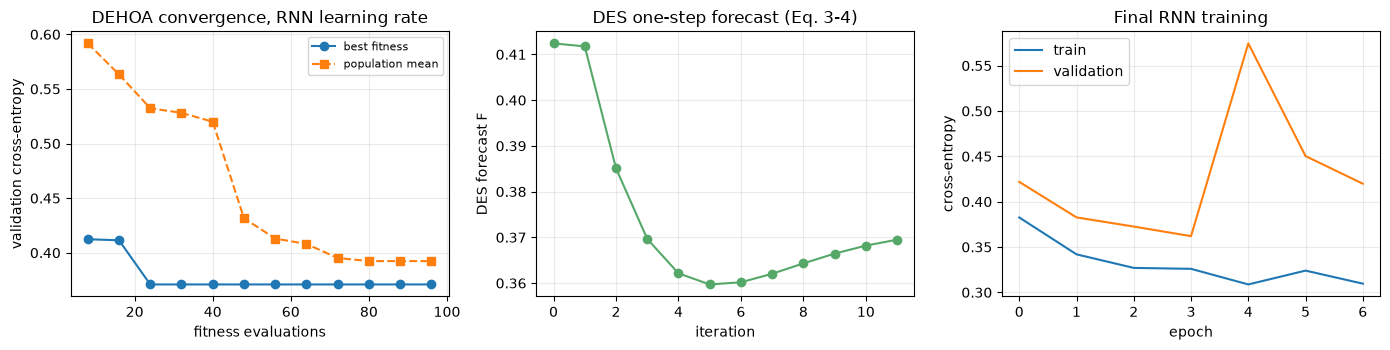

embedding shapes  train(SMOTE) (60000, 32) | validation (8000, 32) | test (22544, 32)


In [13]:
def stage_rnn(S, seed, agents=RNN_AGENTS, iters=RNN_ITERS, fit_n=RNN_FIT_N, warm=RNN_WARM, epochs=FINAL_RNN_EPOCHS, verbose=True):
    # DEHOA 1-D learning-rate search, then the final RNN; returns the embeddings of every split
    t0 = time.time(); sel, C = S["sel"], S["n_classes"]
    r = np.random.default_rng(seed)
    sub, _ = train_test_split(np.arange(len(S["ys"])), train_size=min(fit_n, len(S["ys"]) - 1), stratify=S["ys"], random_state=seed)   # stratified subsample
    Xf, yf = S["Xs"][sub][:, sel], S["ys"][sub]; Xv, yv = S["Xv"][:, sel], S["yv"]
    def fitness(u):
        net = Net(len(sel), (64, 32), C, act="tanh", lr=dec_rnn_lr(u), seed=seed)         # CHOICE: same seed in every call -> deterministic fitness
        net.fit(Xf, yf, warm, bs=128); return net.loss(Xv, yv)
    bx, bf, hist = DEHOA(fitness, 1, agents, iters, seed).run()
    lr = dec_rnn_lr(bx)
    net = Net(len(sel), (64, 32), C, act="tanh", lr=lr, seed=seed)
    th = net.fit(S["Xs"][:, sel], S["ys"], epochs, bs=128, val=(Xv, yv), patience=3)
    emb = lambda X: net.embed(X[:, sel])
    res = dict(lr=lr, net=net, search=hist, train_hist=th, E_s=emb(S["Xs"]), E_c=emb(S["Xc"]), E_v=emb(S["Xv"]), E_t=emb(S["Xt"]),
               evals=hist["evals"][-1], seconds=time.time() - t0)
    if verbose:
        print("RNN search: %d fitness evaluations, best validation CE %.4f at lr = %.2e; final RNN %d epochs, %d parameters (%.0f s)" %
              (res["evals"], bf, lr, len(th["loss"]), net.n_params, res["seconds"]))
    return res

RNN = stage_rnn(SPLIT, SEED)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(RNN["search"]["evals"], RNN["search"]["best"], "o-", label="best fitness"); ax[0].plot(RNN["search"]["evals"], RNN["search"]["mean"], "s--", label="population mean")
ax[0].set_xlabel("fitness evaluations"); ax[0].set_ylabel("validation cross-entropy"); ax[0].set_title("DEHOA convergence, RNN learning rate"); ax[0].legend(fontsize=8)
ax[1].plot(RNN["search"]["forecast"], "o-", color="#55A868"); ax[1].set_xlabel("iteration"); ax[1].set_ylabel("DES forecast F"); ax[1].set_title("DES one-step forecast (Eq. 3-4)")
ax[2].plot(RNN["train_hist"]["loss"], label="train"); ax[2].plot(RNN["train_hist"]["val_loss"], label="validation")
ax[2].set_xlabel("epoch"); ax[2].set_ylabel("cross-entropy"); ax[2].set_title("Final RNN training"); ax[2].legend()
plt.tight_layout(); plt.show()
print("embedding shapes  train(SMOTE) %s | validation %s | test %s" % (RNN["E_s"].shape, RNN["E_v"].shape, RNN["E_t"].shape))

## 5. Stage 3: DEHOA-tuned MLP classifier

A 4-D DEHOA search over `{log10 lr, h1, h2, dropout}`. Each candidate MLP (two ReLU layers, BatchNorm, Dropout) is trained for a few epochs on a fixed stratified subsample of the embeddings and scored by the validation cross-entropy. The best configuration then trains the final MLP (up to `FINAL_MLP_EPOCHS` epochs, early stopping on the validation loss).

MLP search: 375 evaluations, best validation CE 0.2782 -> lr=2.85e-03 h1=110 h2=52 dropout=0.06; final MLP 11 epochs, 9991 parameters (831 s)

DEHOA pipeline on KDDTest+ (seed 42): accuracy 0.7285 | precision 0.7513 | recall 0.7285 | F1 0.7075 | macro-F1 0.5240 | AUC(bin) 0.8876 | AUC(ovr) 0.8566
per-class recall: {'Normal': 0.913, 'DoS': 0.722, 'Probe': 0.674, 'U2R': 0.269, 'R2L': 0.18}


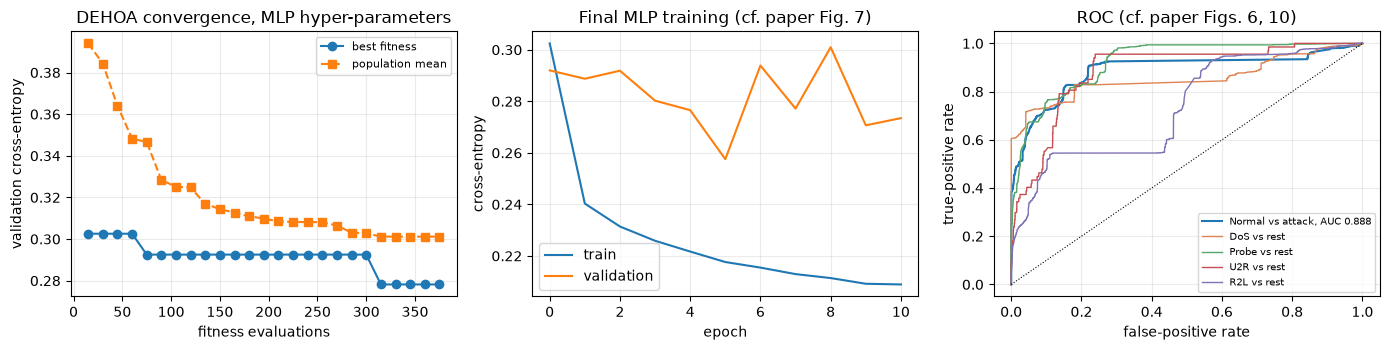

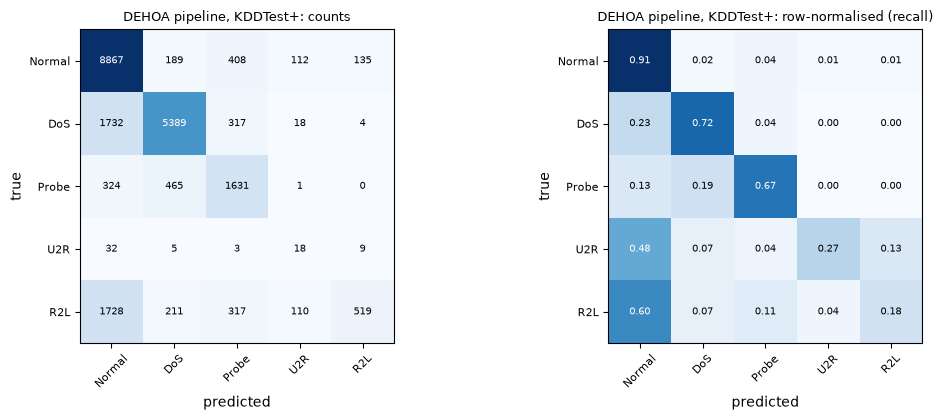

In [14]:
def make_mlp_fitness(S, E, seed, fit_n, fit_epochs):
    # fitness of a point of the unit cube = validation cross-entropy of an MLP trained briefly on a fixed stratified subsample
    C = S["n_classes"]
    sub, _ = train_test_split(np.arange(len(S["ys"])), train_size=min(fit_n, len(S["ys"]) - 1), stratify=S["ys"], random_state=seed)
    Xf, yf = E["E_s"][sub], S["ys"][sub]
    def fitness(u):
        h = dec_mlp(u); net = Net(Xf.shape[1], (h["h1"], h["h2"]), C, act="relu", bn=True, dropout=h["dropout"], lr=h["lr"], seed=seed)
        net.fit(Xf, yf, fit_epochs, bs=256); return net.loss(E["E_v"], S["yv"])
    return fitness

def stage_mlp(S, E, seed, agents=MLP_AGENTS, iters=MLP_ITERS, fit_n=MLP_FIT_N, fit_epochs=MLP_FIT_EPOCHS, epochs=FINAL_MLP_EPOCHS, verbose=True, use_des=True):
    # DEHOA 4-D hyper-parameter search, then the final MLP on the embedding; E = dict(E_s, E_v, E_t)
    t0 = time.time(); C = S["n_classes"]; Xf = E["E_s"]
    bx, bf, hist = DEHOA(make_mlp_fitness(S, E, seed, fit_n, fit_epochs), 4, agents, iters, seed, use_des=use_des).run()
    h = dec_mlp(bx)
    net = Net(Xf.shape[1], (h["h1"], h["h2"]), C, act="relu", bn=True, dropout=h["dropout"], lr=h["lr"], seed=seed)
    th = net.fit(E["E_s"], S["ys"], epochs, bs=256, val=(E["E_v"], S["yv"]), patience=5)
    P = net.predict_proba(E["E_t"]); res = dict(params=h, net=net, search=hist, train_hist=th, P_test=P, metrics=metrics(S["yt"], P, C), best_fitness=bf,
                                                 evals=hist["evals"][-1], seconds=time.time() - t0)
    if verbose:
        print("MLP search: %d evaluations, best validation CE %.4f -> lr=%.2e h1=%d h2=%d dropout=%.2f; final MLP %d epochs, %d parameters (%.0f s)" %
              (res["evals"], bf, h["lr"], h["h1"], h["h2"], h["dropout"], len(th["loss"]), net.n_params, res["seconds"]))
    return res

MLP = stage_mlp(SPLIT, RNN, SEED)
m = MLP["metrics"]
print("\nDEHOA pipeline on KDDTest+ (seed %d): accuracy %.4f | precision %.4f | recall %.4f | F1 %.4f | macro-F1 %.4f | AUC(bin) %.4f | AUC(ovr) %.4f" %
      (SEED, m["acc"], m["prec"], m["rec"], m["f1"], m["macro_f1"], m["auc_bin"], m["auc_ovr"]))
print("per-class recall:", {c: round(float(v), 3) for c, v in zip(NSL_CLASSES, m["recall_per_class"])})
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(MLP["search"]["evals"], MLP["search"]["best"], "o-", label="best fitness"); ax[0].plot(MLP["search"]["evals"], MLP["search"]["mean"], "s--", label="population mean")
ax[0].set_xlabel("fitness evaluations"); ax[0].set_ylabel("validation cross-entropy"); ax[0].set_title("DEHOA convergence, MLP hyper-parameters"); ax[0].legend(fontsize=8)
ax[1].plot(MLP["train_hist"]["loss"], label="train"); ax[1].plot(MLP["train_hist"]["val_loss"], label="validation"); ax[1].set_xlabel("epoch")
ax[1].set_ylabel("cross-entropy"); ax[1].set_title("Final MLP training (cf. paper Fig. 7)"); ax[1].legend()
fpr, tpr, _ = roc_curve(NSL.yte != 0, 1 - MLP["P_test"][:, 0]); ax[2].plot(fpr, tpr, label="Normal vs attack, AUC %.3f" % m["auc_bin"])
for c in range(1, 5):
    f_, t_, _ = roc_curve(NSL.yte == c, MLP["P_test"][:, c]); ax[2].plot(f_, t_, lw=1, label="%s vs rest" % NSL_CLASSES[c], color=CLASS_COLORS[c])
ax[2].plot([0, 1], [0, 1], "k:", lw=0.8); ax[2].set_xlabel("false-positive rate"); ax[2].set_ylabel("true-positive rate"); ax[2].set_title("ROC (cf. paper Figs. 6, 10)"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()
plot_cm(m, NSL_CLASSES, "DEHOA pipeline, KDDTest+")

## 6. Classical baselines and the ablation (Tables 2 and 3)

On the same training part, validation part and test set, the notebook trains

* the **ablation ladder** of Table 2 with a default MLP (`64-32`, ReLU, BatchNorm, dropout 0.2, Adam 1e-3, no DEHOA) on: the raw unscaled 41 features, the Min-Max scaled 41 features (= "MLP without DEHOA", Table 3), the 8 MOI features, the 32-d DEHOA-RNN embedding; the last rung is the full DEHOA pipeline of Section 5;
* an **LSTM** (64 units, a single time step over the 41 scaled features, Keras) as the paper's LSTM baseline (its configuration is not given);
* a **random forest** and an **RBF SVM** (`C = 1`) on the identical 8 MOI features, and a random forest on all 41 features.

BTAD and QSVM-IGWO are not re-implemented; the paper's numbers for them are quoted in the final comparison.

In [15]:
def run_extras(B, S, rnn, mlp, seed, verbose=True):
    C = S["n_classes"]; sel = S["sel"]; yt = S["yt"]; out = {}; t0 = time.time()
    def default_mlp(Xs, Xv, Xt):
        net = Net(Xs.shape[1], (64, 32), C, act="relu", bn=True, dropout=0.2, lr=1e-3, seed=seed)
        net.fit(Xs, S["ys"], DEFAULT_MLP_EPOCHS, bs=256, val=(Xv, S["yv"]), patience=5)
        return metrics(yt, net.predict_proba(Xt), C)
    Xs_raw = B.scaler.inverse_transform(S["Xs"]).astype(np.float32); Xv_raw = B.scaler.inverse_transform(S["Xv"]).astype(np.float32)
    out["abl1_raw41"] = default_mlp(Xs_raw, Xv_raw, B.Xte_raw)                                   # no pre-processing
    out["abl2_minmax41"] = default_mlp(S["Xs"], S["Xv"], S["Xt"])                                 # + Min-Max  (= "MLP, no DEHOA")
    out["abl3_moi8"] = default_mlp(S["Xs"][:, sel], S["Xv"][:, sel], S["Xt"][:, sel])             # + MOI feature selection
    out["abl4_dehoa_rnn"] = default_mlp(rnn["E_s"], rnn["E_v"], rnn["E_t"])                       # + DEHOA-RNN embedding
    out["abl5_full"] = mlp["metrics"]                                                              # + DEHOA-MLP = full pipeline
    # random forest / SVM on the identical 8 inputs, random forest on all 41
    rf8 = RandomForestClassifier(n_estimators=100, n_jobs=2, random_state=seed).fit(S["Xs"][:, sel], S["ys"])
    out["rf8"] = metrics(yt, rf8.predict_proba(S["Xt"][:, sel]), C)
    rf41 = RandomForestClassifier(n_estimators=100, n_jobs=2, random_state=seed).fit(S["Xs"], S["ys"])
    out["rf41"] = metrics(yt, rf41.predict_proba(S["Xt"]), C)
    sub = np.random.default_rng(seed).choice(len(S["ys"]), min(SVC_N, len(S["ys"])), replace=False)    # CHOICE: the SVM trains on a subsample
    svc = SVC(kernel="rbf", C=1.0, probability=True, random_state=seed).fit(S["Xs"][sub][:, sel], S["ys"][sub])
    out["svc8"] = metrics(yt, svc.predict_proba(S["Xt"][:, sel]), C)
    if keras is not None:                                                                          # LSTM baseline (Keras)
        keras.utils.set_random_seed(seed); keras.backend.clear_session()
        idx = np.random.default_rng(seed).choice(len(S["ys"]), min(LSTM_TRAIN_N, len(S["ys"])), replace=False)
        lstm = keras.Sequential([keras.Input((1, S["Xs"].shape[1])), layers.LSTM(64), layers.Dense(32, activation="relu"), layers.Dense(C, activation="softmax")])
        lstm.compile(keras.optimizers.Adam(1e-3), "sparse_categorical_crossentropy")
        lstm.fit(S["Xs"][idx][:, None, :], S["ys"][idx], epochs=LSTM_EPOCHS, batch_size=256, verbose=0)
        out["lstm"] = metrics(yt, lstm.predict(S["Xt"][:, None, :], verbose=0, batch_size=2048), C); out["lstm_params"] = lstm.count_params()
    out["seconds"] = time.time() - t0
    if verbose: print("baselines + ablation for seed %d: %.0f s" % (seed, out["seconds"]))
    return out

RUNS = {}
EXTRAS = run_extras(NSL, SPLIT, RNN, MLP, SEED)
RUNS[SEED] = dict(dehoa=MLP["metrics"], rnn_lr=RNN["lr"], mlp_params=MLP["params"], seconds=RNN["seconds"] + MLP["seconds"], extras=EXTRAS,
                  n_params=(RNN["net"].n_params, MLP["net"].n_params))
tab = [row("DEHOA pipeline (full)", EXTRAS["abl5_full"]), row("MLP, no DEHOA (Min-Max 41 features)", EXTRAS["abl2_minmax41"]),
       row("LSTM (Keras)", EXTRAS["lstm"]) if "lstm" in EXTRAS else None,
       row("RandomForest, 8 MOI features", EXTRAS["rf8"]), row("RandomForest, all 41 features", EXTRAS["rf41"]), row("SVC rbf, 8 MOI features", EXTRAS["svc8"])]
display(pd.DataFrame([t for t in tab if t]).round(4))
abl = pd.DataFrame([row(n, EXTRAS[k]) for n, k in (("no pre-processing (raw 41)", "abl1_raw41"), ("+ Min-Max", "abl2_minmax41"), ("+ MOI top-8", "abl3_moi8"),
                                                    ("+ DEHOA-RNN embedding", "abl4_dehoa_rnn"), ("full DEHOA pipeline", "abl5_full"))])
print("\nAblation ladder (cf. paper Table 2), seed %d:" % SEED); display(abl.round(4))

baselines + ablation for seed 42: 180 s


,model,accuracy,precision,recall,F1,macro-F1,AUC (bin)
0,DEHOA pipeline (full),0.7285,0.7513,0.7285,0.7075,0.5240,0.8876
1,"MLP, no DEHOA (Min-Max 41 features)",0.7775,0.7997,0.7775,0.7483,0.5647,0.9385
2,LSTM (Keras),0.7611,0.7934,0.7611,0.7455,0.5897,0.8986
3,"RandomForest, 8 MOI features",0.7457,0.7922,0.7457,0.7128,0.5322,0.9067
4,"RandomForest, all 41 features",0.7564,0.8126,0.7564,0.7203,0.5909,0.9605
5,"SVC rbf, 8 MOI features",0.6761,0.7328,0.6761,0.6661,0.4674,0.8316



Ablation ladder (cf. paper Table 2), seed 42:


,model,accuracy,precision,recall,F1,macro-F1,AUC (bin)
0,no pre-processing (raw 41),0.7143,0.6768,0.7143,0.6841,0.4512,0.9238
1,+ Min-Max,0.7775,0.7997,0.7775,0.7483,0.5647,0.9385
2,+ MOI top-8,0.7424,0.7755,0.7424,0.7230,0.5332,0.8782
3,+ DEHOA-RNN embedding,0.7066,0.7357,0.7066,0.6872,0.5019,0.8569
4,full DEHOA pipeline,0.7285,0.7513,0.7285,0.7075,0.5240,0.8876


### 6.1 Repeating the pipeline over several seeds

Each seed redraws the validation split, the capped sample and SMOTE, the network initialisations and both DEHOA searches. The test set (`KDDTest+`) is fixed. The paper reports 10 runs; `N_RUNS` is set in the configuration cell.

In [16]:
for sd in RUN_SEEDS[1:]:
    t0 = time.time()
    S_i = make_split(NSL, sd); rnn_i = stage_rnn(S_i, sd, verbose=False)
    mlp_i = stage_mlp(S_i, rnn_i, sd, verbose=False); ex_i = run_extras(NSL, S_i, rnn_i, mlp_i, sd, verbose=False)
    RUNS[sd] = dict(dehoa=mlp_i["metrics"], rnn_lr=rnn_i["lr"], mlp_params=mlp_i["params"], seconds=rnn_i["seconds"] + mlp_i["seconds"], extras=ex_i,
                    n_params=(rnn_i["net"].n_params, mlp_i["net"].n_params))
    print("seed %d: DEHOA accuracy %.4f F1 %.4f | rnn lr %.2e | mlp %s | %.0f s" % (sd, mlp_i["metrics"]["acc"], mlp_i["metrics"]["f1"], rnn_i["lr"],
          {k: (round(v, 4) if isinstance(v, float) else v) for k, v in mlp_i["params"].items()}, time.time() - t0))
    del S_i, rnn_i, mlp_i
METHODS = [("DEHOA pipeline", lambda r: r["dehoa"]), ("MLP, no DEHOA (Min-Max 41)", lambda r: r["extras"]["abl2_minmax41"]),
           ("LSTM", lambda r: r["extras"].get("lstm")), ("RandomForest 8 MOI", lambda r: r["extras"]["rf8"]),
           ("RandomForest 41", lambda r: r["extras"]["rf41"]), ("SVC rbf 8 MOI", lambda r: r["extras"]["svc8"])]
def summarise(getter, key):
    v = [getter(RUNS[s])[key] for s in RUN_SEEDS if getter(RUNS[s]) is not None]; return np.mean(v), (np.std(v, ddof=1) if len(v) > 1 else np.nan), len(v)
rows = []
for name, g in METHODS:
    if g(RUNS[SEED]) is None: continue
    d = {"model": name}
    for k, lab in (("acc", "accuracy"), ("prec", "precision"), ("rec", "recall"), ("f1", "F1")):
        mu, sd_, n = summarise(g, k); d[lab] = "%.4f +- %.4f" % (mu, sd_) if n > 1 else "%.4f" % mu
    rows.append(d)
print("test metrics over %d seed(s) (mean +- sample std):" % len(RUN_SEEDS)); display(pd.DataFrame(rows))

seed 43: DEHOA accuracy 0.7494 F1 0.7272 | rnn lr 3.59e-02 | mlp {'lr': 0.0091, 'h1': 24, 'h2': 38, 'dropout': 0.0113} | 916 s


seed 44: DEHOA accuracy 0.7572 F1 0.7367 | rnn lr 3.19e-02 | mlp {'lr': 0.0085, 'h1': 88, 'h2': 29, 'dropout': 0.0116} | 949 s
test metrics over 3 seed(s) (mean +- sample std):


,model,accuracy,precision,recall,F1
0,DEHOA pipeline,0.7450 +- 0.0148,0.7716 +- 0.0176,0.7450 +- 0.0148,0.7238 +- 0.0149
1,"MLP, no DEHOA (Min-Max 41)",0.7705 +- 0.0176,0.8086 +- 0.0104,0.7705 +- 0.0176,0.7438 +- 0.0157
2,LSTM,0.7759 +- 0.0149,0.8091 +- 0.0164,0.7759 +- 0.0149,0.7621 +- 0.0173
3,RandomForest 8 MOI,0.7427 +- 0.0078,0.7885 +- 0.0078,0.7427 +- 0.0078,0.7101 +- 0.0076
4,RandomForest 41,0.7614 +- 0.0053,0.8168 +- 0.0038,0.7614 +- 0.0053,0.7283 +- 0.0076
5,SVC rbf 8 MOI,0.6786 +- 0.0033,0.7329 +- 0.0043,0.6786 +- 0.0033,0.6679 +- 0.0029


## 7. DEHOA-QNN: the quantum back end

The VQC replaces the MLP. Its input is the 32-d RNN embedding, which has to be squeezed into 4 qubits; the paper does not say how, so a PCA with 4 components (fitted on the training embedding only) followed by Min-Max scaling to [0, 1] is used, and the circuit encodes each value `f` as `R_y(f pi)`. The scatter plots show **real** training records (not the SMOTE copies) in the QNN input space: first the raw PCA coordinates, then the angles `f pi` in [0, pi] that the circuit actually receives.

PCA(4) of the 32-d embedding keeps 75.4 % of the variance; QNN input shapes: train (60000, 4), validation (8000, 4), test (22544, 4)


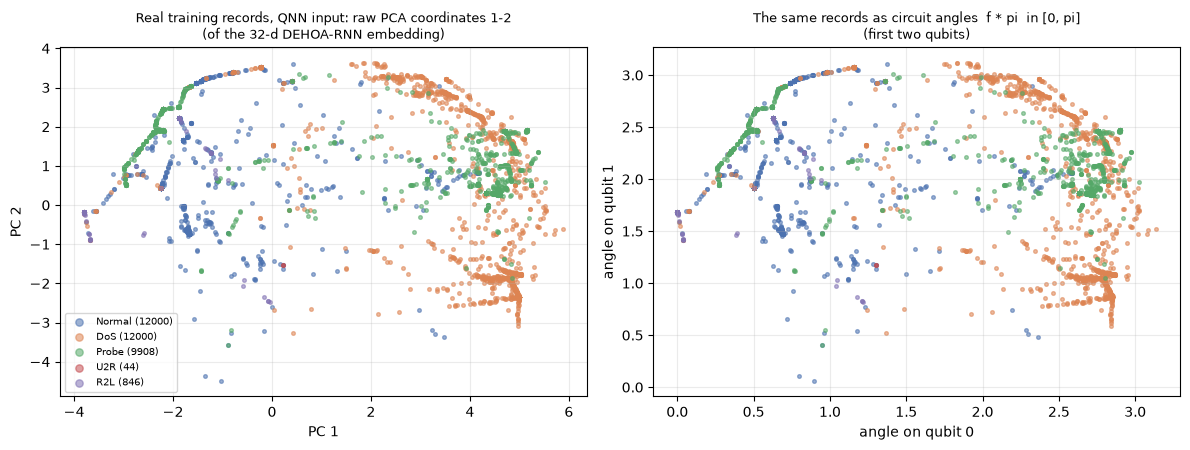

In [17]:
pca4 = PCA(n_components=QNN_QUBITS, random_state=SEED).fit(RNN["E_s"])               # fitted on the (SMOTE-balanced) training embedding only
Z_s = pca4.transform(RNN["E_s"]); zmin, zmax = Z_s.min(0), Z_s.max(0)
to_unit = lambda Z: np.clip((Z - zmin) / (zmax - zmin + 1e-12), 0, 1).astype(np.float64)       # test / validation values clipped to the training range
Q = dict(s=to_unit(Z_s), v=to_unit(pca4.transform(RNN["E_v"])), t=to_unit(pca4.transform(RNN["E_t"])), c=to_unit(pca4.transform(RNN["E_c"])))
print("PCA(4) of the 32-d embedding keeps %.1f %% of the variance; QNN input shapes: train %s, validation %s, test %s" %
      (100 * pca4.explained_variance_ratio_.sum(), Q["s"].shape, Q["v"].shape, Q["t"].shape))
ri = np.random.default_rng(SEED).choice(len(Q["c"]), min(4000, len(Q["c"])), replace=False)
Zc = pca4.transform(RNN["E_c"])[ri]; yc_ = SPLIT["yc"][ri]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for c in range(5):
    m_ = yc_ == c
    ax[0].scatter(Zc[m_, 0], Zc[m_, 1], s=7, alpha=0.55, color=CLASS_COLORS[c], label="%s (%d)" % (NSL_CLASSES[c], (SPLIT["yc"] == c).sum()))
    ax[1].scatter(np.pi * Q["c"][ri][m_, 0], np.pi * Q["c"][ri][m_, 1], s=7, alpha=0.55, color=CLASS_COLORS[c])
ax[0].set_title("Real training records, QNN input: raw PCA coordinates 1-2\n(of the 32-d DEHOA-RNN embedding)", fontsize=9); ax[0].set_xlabel("PC 1"); ax[0].set_ylabel("PC 2"); ax[0].legend(markerscale=2, fontsize=7)
ax[1].set_title("The same records as circuit angles  f * pi  in [0, pi]\n(first two qubits)", fontsize=9); ax[1].set_xlabel("angle on qubit 0"); ax[1].set_ylabel("angle on qubit 1")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The circuit below is the one that is executed (PennyLane `default.qubit`, exact statevector): 4 qubits, angle encoding `R_y(f_i pi)`, then 4 variational layers, each one `R_y(theta)` per qubit followed by a **circular CNOT ring** `0->1->2->3->0`, and Pauli-Z expectation values on all four qubits. The 4 expectation values go through a classical Dense (softmax) layer to the 5 classes.

**Assumptions where the paper is silent or inconsistent.** (1) Sec. 3.6 says "4 variational layers of Ry rotations" and "16 variational parameters" but a few lines later "trainable Rx, Ry, Rz rotations"; 4 layers x 4 qubits x 3 rotations would be 48 parameters, so the 16-parameter / `R_y`-only reading is used. (2) The order inside a layer (rotations, then the CNOT ring) is assumed. (3) The mapping 32-d embedding -> 4 angles is the PCA described above. (4) The Dense read-out has 4 x 5 + 5 = 25 weights that DEHOA does not search; it is refitted by softmax regression inside every fitness evaluation.

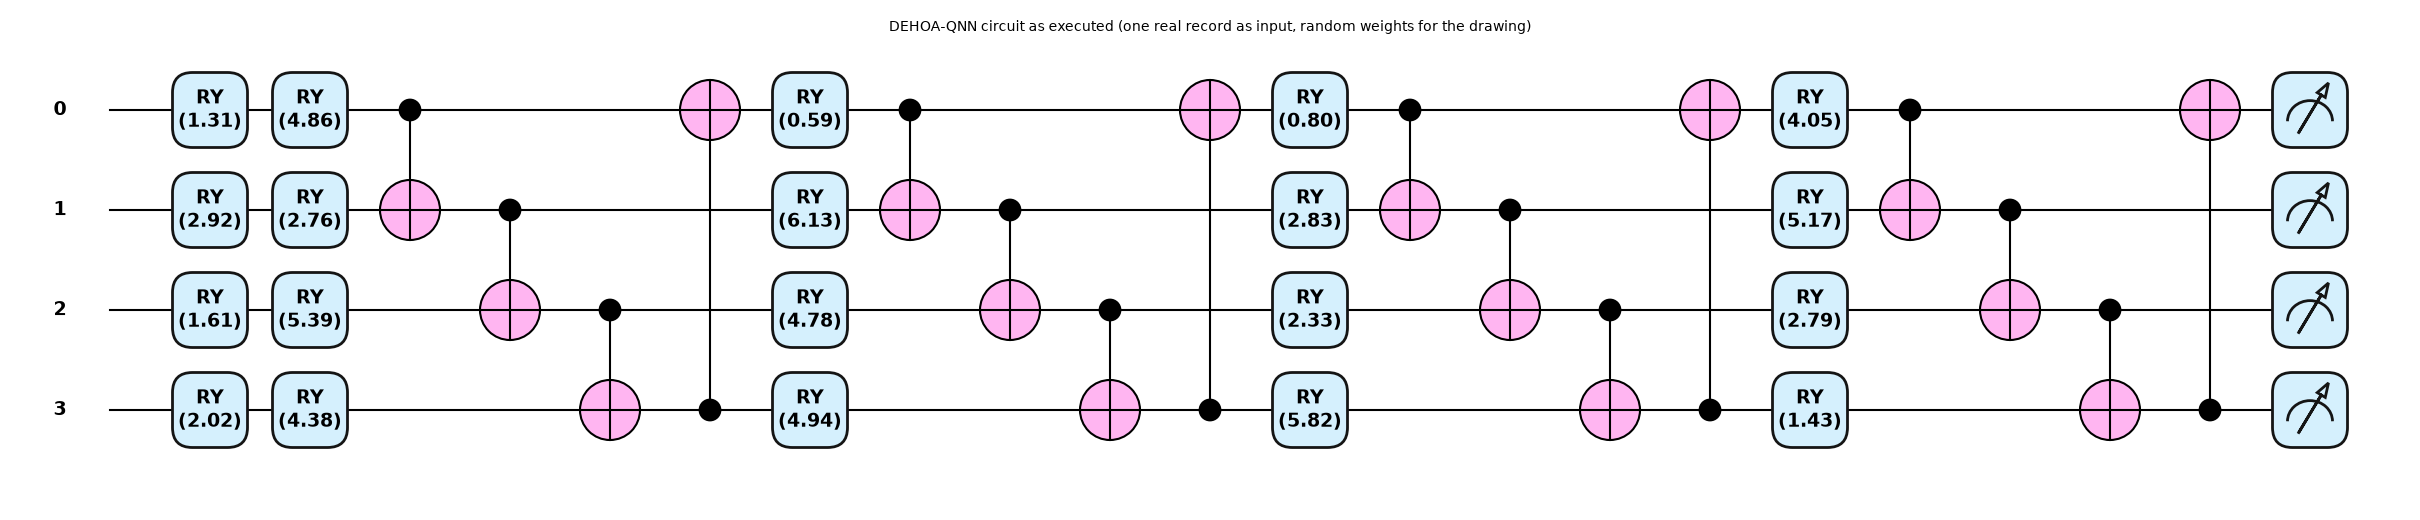

qubits: 4 | depth: 21 | gates: {'RY': 20, 'CNOT': 16} | trainable parameters: 16 (= 4 layers x 4 qubits)
PennyLane circuit vs independent NumPy statevector simulation: max |difference| = 2.64e-16
batched execution (parameter broadcasting) output shape: (5, 4)


In [18]:
dev = qml.device("default.qubit", wires=QNN_QUBITS)

@qml.qnode(dev, interface="numpy", diff_method=None)
def vqc(x, w):
    # x: features in [0, 1] (shape (4,) or batch (N, 4)); w: (QNN_LAYERS, QNN_QUBITS) angles
    for i in range(QNN_QUBITS):
        qml.RY(x[..., i] * np.pi, wires=i)                       # angle encoding R_y(f_i * pi)
    for l in range(QNN_LAYERS):
        for i in range(QNN_QUBITS):
            qml.RY(w[l, i], wires=i)                             # trainable rotations (16 parameters in total)
        for i in range(QNN_QUBITS):
            qml.CNOT(wires=[i, (i + 1) % QNN_QUBITS])            # circular CNOT ring
    return [qml.expval(qml.PauliZ(i)) for i in range(QNN_QUBITS)]

x_demo = Q["c"][0].copy(); w_demo = np.random.default_rng(SEED).uniform(0, 2 * np.pi, (QNN_LAYERS, QNN_QUBITS))
fig, ax = qml.draw_mpl(vqc, decimals=2, style="pennylane")(x_demo, w_demo)
fig.suptitle("DEHOA-QNN circuit as executed (one real record as input, random weights for the drawing)", fontsize=10); plt.show()
sp = qml.specs(vqc, level="device")(x_demo, w_demo); res = sp["resources"]
print("qubits: %d | depth: %d | gates: %s | trainable parameters: %d (= %d layers x %d qubits)" %
      (sp.num_device_wires, res.depth, dict(res.gate_types), w_demo.size, QNN_LAYERS, QNN_QUBITS))
assert w_demo.size == 16 and res.gate_types.get("RY", 0) == QNN_QUBITS + 16 and res.gate_types.get("CNOT", 0) == 16

# equivalence check: an independent NumPy statevector simulation of the same gate list gives the same expectation values
def ry(a): c, s = np.cos(a / 2), np.sin(a / 2); return np.array([[c, -s], [s, c]])
def apply1(psi, U, q, n=QNN_QUBITS): return np.moveaxis(np.tensordot(U, np.moveaxis(psi, q, 0), axes=(1, 0)), 0, q)
def applycx(psi, c, t, n=QNN_QUBITS):
    psi = psi.copy(); idx = [slice(None)] * n; idx[c] = 1; sub = psi[tuple(idx)]
    tt = t if t < c else t - 1; psi[tuple(idx)] = np.flip(sub, axis=tt); return psi
def numpy_vqc(x, w):
    psi = np.zeros((2,) * QNN_QUBITS); psi[(0,) * QNN_QUBITS] = 1.0
    for i in range(QNN_QUBITS): psi = apply1(psi, ry(x[i] * np.pi), i)
    for l in range(QNN_LAYERS):
        for i in range(QNN_QUBITS): psi = apply1(psi, ry(w[l, i]), i)
        for i in range(QNN_QUBITS): psi = applycx(psi, i, (i + 1) % QNN_QUBITS)
    return np.array([float(((psi ** 2) * (1 - 2 * np.indices((2,) * QNN_QUBITS)[q])).sum()) for q in range(QNN_QUBITS)])
d_eq = np.abs(np.array(vqc(x_demo, w_demo)) - numpy_vqc(x_demo, w_demo)).max()
print("PennyLane circuit vs independent NumPy statevector simulation: max |difference| = %.2e" % d_eq); assert d_eq < 1e-9
xb = Q["c"][:5]; zb = np.stack(vqc(xb, w_demo), axis=1); print("batched execution (parameter broadcasting) output shape:", zb.shape)
assert np.allclose(zb[0], np.array(vqc(Q["c"][0], w_demo)))

## 8. Training the VQC with DEHOA

DEHOA searches the 16 angles in [0, 2 pi] directly, with no gradients (the paper's way of "sidestepping the parameter-shift rule"). The fitness of a candidate circuit is the validation cross-entropy of the Dense read-out, which is refitted (softmax regression on the 4 Pauli-Z expectation values of a stratified training subsample) for every candidate. The final read-out is fitted on the whole training embedding. Reference points on the same 4 angle inputs: a random untrained circuit with a fitted read-out, a softmax regression on the 4 angles without any circuit, and classical RF / RBF-SVC / small MLP.

QNN search: 600 evaluations, best validation CE 0.5751 (249 s); test accuracy 0.6785, F1 0.6569


,model,accuracy,precision,recall,F1,macro-F1,AUC (bin)
0,"DEHOA-QNN (VQC, 16 parameters)",0.6785,0.7042,0.6785,0.6569,0.4684,0.8366
1,"QNN, random circuit + fitted read-out",0.6088,0.6505,0.6088,0.6164,0.3824,0.8677
2,softmax regression on the 4 angles (no circuit),0.6728,0.7046,0.6728,0.6493,0.4719,0.7348
3,RandomForest on the 4 angles,0.7420,0.7684,0.7420,0.7212,0.5429,0.8959
4,SVC rbf on the 4 angles,0.7054,0.7347,0.7054,0.6809,0.5034,0.8537
5,small MLP on the 4 angles,0.6983,0.7351,0.6983,0.6777,0.4974,0.8611
6,DEHOA-MLP on the 32-d embedding (Section 5),0.7285,0.7513,0.7285,0.7075,0.5240,0.8876


QNN per-class recall: {'Normal': 0.909, 'DoS': 0.63, 'Probe': 0.563, 'U2R': 0.433, 'R2L': 0.132}


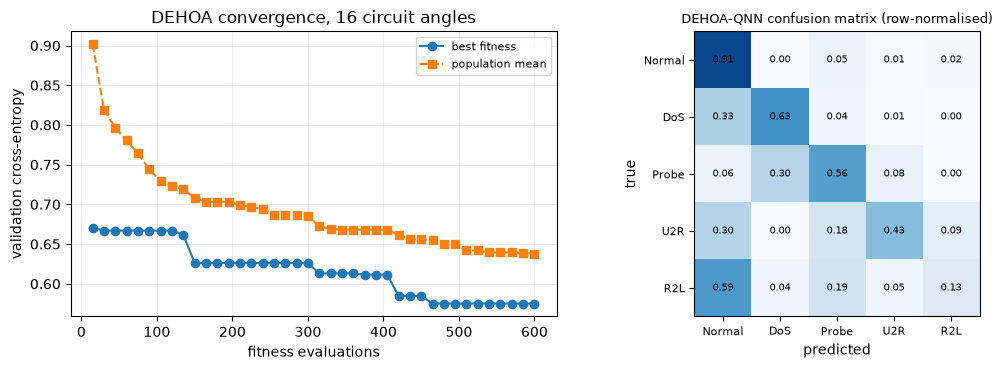

In [19]:
def qfeat(Xq, w): return np.stack(vqc(Xq, w.reshape(QNN_LAYERS, QNN_QUBITS)), axis=1)

def stage_qnn(S, Q, seed, agents=QNN_AGENTS, iters=QNN_ITERS, fit_n=QNN_FIT_N, val_n=QNN_VAL_N, verbose=True):
    t0 = time.time(); C = S["n_classes"]
    sub, _ = train_test_split(np.arange(len(S["ys"])), train_size=min(fit_n, len(S["ys"]) - 1), stratify=S["ys"], random_state=seed)
    vi = np.random.default_rng(seed).choice(len(S["yv"]), min(val_n, len(S["yv"])), replace=False)
    Qf, yf, Qv, yv = Q["s"][sub], S["ys"][sub], Q["v"][vi], S["yv"][vi]
    def fitness(u):
        w = u * 2 * np.pi; head = LogisticRegression(C=10.0, max_iter=200).fit(qfeat(Qf, w), yf)
        return log_loss(yv, head.predict_proba(qfeat(Qv, w)), labels=list(range(C)))
    bx, bf, hist = DEHOA(fitness, QNN_LAYERS * QNN_QUBITS, agents, iters, seed).run()
    w = bx * 2 * np.pi
    head = LogisticRegression(C=10.0, max_iter=500).fit(qfeat(Q["s"], w), S["ys"])
    P = head.predict_proba(qfeat(Q["t"], w)); m = metrics(S["yt"], P, C)
    # reference points on the same 4 angles
    w0 = np.random.default_rng(seed + 7).uniform(0, 2 * np.pi, QNN_LAYERS * QNN_QUBITS)
    P0 = LogisticRegression(C=10.0, max_iter=500).fit(qfeat(Q["s"], w0), S["ys"]).predict_proba(qfeat(Q["t"], w0))
    P_lin = LogisticRegression(C=10.0, max_iter=500).fit(Q["s"], S["ys"]).predict_proba(Q["t"])
    rf = RandomForestClassifier(n_estimators=100, n_jobs=2, random_state=seed).fit(Q["s"], S["ys"]); P_rf = rf.predict_proba(Q["t"])
    ss = np.random.default_rng(seed).choice(len(S["ys"]), min(SVC_N, len(S["ys"])), replace=False)
    P_svc = SVC(kernel="rbf", C=1.0, probability=True, random_state=seed).fit(Q["s"][ss], S["ys"][ss]).predict_proba(Q["t"])
    mlp4 = Net(QNN_QUBITS, (16, 8), C, act="relu", bn=True, dropout=0.1, lr=1e-3, seed=seed); mlp4.fit(Q["s"].astype(np.float32), S["ys"], DEFAULT_MLP_EPOCHS, bs=256)
    P_m4 = mlp4.predict_proba(Q["t"].astype(np.float32))
    refs = {"QNN, random circuit + fitted read-out": metrics(S["yt"], P0, C), "softmax regression on the 4 angles (no circuit)": metrics(S["yt"], P_lin, C),
            "RandomForest on the 4 angles": metrics(S["yt"], P_rf, C), "SVC rbf on the 4 angles": metrics(S["yt"], P_svc, C), "small MLP on the 4 angles": metrics(S["yt"], P_m4, C)}
    if verbose: print("QNN search: %d evaluations, best validation CE %.4f (%.0f s); test accuracy %.4f, F1 %.4f" % (hist["evals"][-1], bf, time.time() - t0, m["acc"], m["f1"]))
    return dict(w=w, metrics=m, search=hist, refs=refs, P=P, best_fitness=bf, seconds=time.time() - t0)

QNN = stage_qnn(SPLIT, Q, SEED)
rows = [row("DEHOA-QNN (VQC, 16 parameters)", QNN["metrics"])] + [row(k, v) for k, v in QNN["refs"].items()] + [row("DEHOA-MLP on the 32-d embedding (Section 5)", MLP["metrics"])]
display(pd.DataFrame(rows).round(4))
print("QNN per-class recall:", {c: round(float(v), 3) for c, v in zip(NSL_CLASSES, QNN["metrics"]["recall_per_class"])})
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(QNN["search"]["evals"], QNN["search"]["best"], "o-", label="best fitness"); ax[0].plot(QNN["search"]["evals"], QNN["search"]["mean"], "s--", label="population mean")
ax[0].set_xlabel("fitness evaluations"); ax[0].set_ylabel("validation cross-entropy"); ax[0].set_title("DEHOA convergence, 16 circuit angles"); ax[0].legend(fontsize=8)
ax[1].imshow(QNN["metrics"]["cm"] / np.maximum(QNN["metrics"]["cm"].sum(1, keepdims=True), 1), cmap="Blues", vmin=0, vmax=1); ax[1].grid(False)
ax[1].set_xticks(range(5)); ax[1].set_xticklabels(NSL_CLASSES, fontsize=8); ax[1].set_yticks(range(5)); ax[1].set_yticklabels(NSL_CLASSES, fontsize=8)
for i in range(5):
    for j in range(5): ax[1].text(j, i, "%.2f" % (QNN["metrics"]["cm"][i, j] / max(QNN["metrics"]["cm"][i].sum(), 1)), ha="center", va="center", fontsize=7)
ax[1].set_title("DEHOA-QNN confusion matrix (row-normalised)", fontsize=9); ax[1].set_xlabel("predicted"); ax[1].set_ylabel("true")
plt.tight_layout(); plt.show()

## 9. Optimiser comparison (Table 6, reduced budget)

The paper compares DEHOA with HOA without DES, random search, grid search and Bayesian optimisation (Optuna TPE) at a matched budget of about 375 evaluations over 10 runs. Here every method gets the same, much smaller budget `OPT_LEVELS ** 4` evaluations of a cheaper fitness, and `OPT_REPS` repetitions (grid search is deterministic, one run). TPE is skipped (Optuna is not installed). The final MLP of every method is trained on the same embedding of the main run and scored on `KDDTest+`.

In [20]:
def run_optimiser_comparison(S, E, seed):
    budget = OPT_LEVELS ** 4; side = int(round(math.sqrt(budget)))
    fit = make_mlp_fitness(S, E, seed, OPT_FIT_N, OPT_EPOCHS); results = {}
    def finish(u):
        h = dec_mlp(u); net = Net(E["E_s"].shape[1], (h["h1"], h["h2"]), S["n_classes"], act="relu", bn=True, dropout=h["dropout"], lr=h["lr"], seed=seed)
        net.fit(E["E_s"], S["ys"], FINAL_MLP_EPOCHS, bs=256, val=(E["E_v"], S["yv"]), patience=5)
        return metrics(S["yt"], net.predict_proba(E["E_t"]), S["n_classes"])["f1"]
    for name in ("DEHOA", "HOA only (no DES)", "Random search", "Grid search"):
        vals = []
        for rep in range(1 if name == "Grid search" else OPT_REPS):
            sd = seed + 100 + rep
            if name == "DEHOA": bx, bf, _ = DEHOA(fit, 4, side, side, sd, use_des=True).run()
            elif name == "HOA only (no DES)": bx, bf, _ = DEHOA(fit, 4, side, side, sd, use_des=False).run()
            elif name == "Random search":
                cand = np.random.default_rng(sd).random((budget, 4)); fs = [fit(c) for c in cand]; bx, bf = cand[int(np.argmin(fs))], min(fs)
            else:
                lv = (np.arange(OPT_LEVELS) + 0.5) / OPT_LEVELS
                cand = np.array(np.meshgrid(lv, lv, lv, lv)).reshape(4, -1).T; fs = [fit(c) for c in cand]; bx, bf = cand[int(np.argmin(fs))], min(fs)
            vals.append((bf, finish(bx)))
        results[name] = vals
    return budget, results

t0 = time.time(); OPT_BUDGET, OPT = run_optimiser_comparison(SPLIT, RNN, SEED)
tab = [{"method": k, "evaluations": OPT_BUDGET, "runs": len(v), "best validation CE": "%.4f" % np.mean([a for a, _ in v]), "test F1 (mean)": "%.4f" % np.mean([b for _, b in v]),
        "test F1 (runs)": ", ".join("%.4f" % b for _, b in v)} for k, v in OPT.items()]
display(pd.DataFrame(tab)); print("optimiser comparison: %.0f s (paper Table 6: DEHOA 0.7326, HOA-only 0.7365, random 0.7374, grid 0.7320, TPE 0.7401)" % (time.time() - t0))

,method,evaluations,runs,best validation CE,test F1 (mean),test F1 (runs)
0,DEHOA,81,2,0.2829,0.6844,"0.6817, 0.6871"
1,HOA only (no DES),81,2,0.3085,0.6795,"0.6712, 0.6879"
2,Random search,81,2,0.2816,0.6710,"0.6681, 0.6740"
3,Grid search,81,1,0.3494,0.6912,0.6912


optimiser comparison: 318 s (paper Table 6: DEHOA 0.7326, HOA-only 0.7365, random 0.7374, grid 0.7320, TPE 0.7401)


## 10. Cross-dataset check on UNSW-NB15 (Table 7)

The paper applies "the identical three-stage architecture" to UNSW-NB15 (10 classes) and reports accuracy 0.969 and weighted F1 0.974 from a single run, with the data "split 80/20 after SMOTE". Two protocols are run here with the same code:

* **official partitions** (leak-free): the official training partition is split, capped and SMOTE-balanced exactly like NSL-KDD, DEHOA searches the learning rate and the MLP hyper-parameters (smaller budgets `UNSW_RNN`, `UNSW_MLP`), and the official testing partition is the test set;
* **paper protocol**: real records of both partitions are capped, SMOTE is applied to the whole pool, and only *then* is the pool split 80/20. The test fold then contains synthetic neighbours of training records and real records that have near-duplicates in training. The hyper-parameters found in the first protocol are reused (documented shortcut).

real training part 149039 | capped real 34258 | after SMOTE 50000 | validation 8000 | test 82332
class counts  real(capped) -> SMOTE: {'Normal': (5000, 5000), 'Generic': (5000, 5000), 'Exploits': (5000, 5000), 'Fuzzers': (5000, 5000), 'DoS': (5000, 5000), 'Reconnaissance': (5000, 5000), 'Analysis': (1700, 5000), 'Backdoor': (1484, 5000), 'Shellcode': (963, 5000), 'Worms': (111, 5000)}


RNN search: 96 fitness evaluations, best validation CE 1.3405 at lr = 2.78e-02; final RNN 10 epochs, 2986 parameters (37 s)


MLP search: 80 evaluations, best validation CE 1.3222 -> lr=2.00e-02 h1=61 h2=14 dropout=0.07; final MLP 6 epochs, 3181 parameters (162 s)


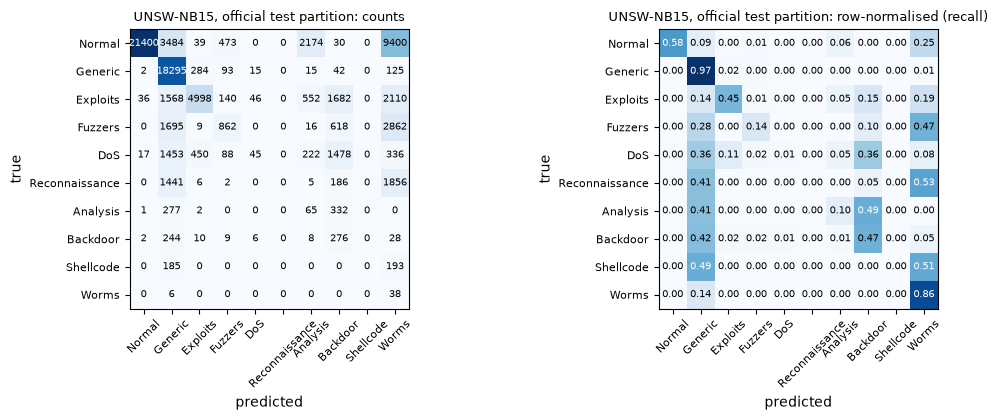

real training part 36000 | capped real 36691 | after SMOTE 36000 | validation 4000 | test 10000
class counts  real(capped) -> SMOTE: {'Normal': (5000, 3600), 'Generic': (5000, 3600), 'Exploits': (5000, 3600), 'Fuzzers': (5000, 3600), 'DoS': (5000, 3600), 'Reconnaissance': (5000, 3600), 'Analysis': (2677, 3600), 'Backdoor': (2329, 3600), 'Shellcode': (1511, 3600), 'Worms': (174, 3600)}


,model,accuracy,precision,recall,F1,macro-F1,AUC (bin)
0,"DEHOA pipeline, official partitions (leak-free)",0.5585,0.7697,0.5585,0.6039,0.2482,0.9117
1,"DEHOA pipeline, paper protocol (SMOTE then 80/...",0.3582,0.3918,0.3582,0.3049,0.3049,0.9200
2,"RandomForest (41 features), official partition...",0.6732,0.8576,0.6732,0.7292,0.4507,0.9680
3,"RandomForest (41 features), paper protocol (SM...",0.7188,0.7331,0.7188,0.7227,0.7227,0.9873


UNSW-NB15 total: 254 s | paper Table 7: accuracy 0.969, precision 0.983, recall 0.969, F1 0.974 (single run)


In [21]:
def paper_protocol_split(B, seed, cap=UNSW_CAP):
    # SMOTE on the whole pool of real records first, then a stratified 80/20 split (what Sec. 4.8 describes)
    r = np.random.default_rng(seed); Xall = np.vstack([B.Xtr_raw, B.Xte_raw]); yall = np.concatenate([B.ytr, B.yte])
    Xall = MinMaxScaler().fit_transform(Xall).astype(np.float32)
    keep = np.concatenate([r.choice(np.where(yall == c)[0], min(cap, (yall == c).sum()), replace=False) for c in range(B.n_classes)])
    Xc, yc = Xall[keep], yall[keep]
    Xs, ys = SMOTE(random_state=seed, k_neighbors=int(max(1, min(5, np.bincount(yc).min() - 1)))).fit_resample(Xc, yc)
    Xa, Xb, ya, yb = train_test_split(Xs, ys, test_size=0.2, stratify=ys, random_state=seed)
    Xa, Xv, ya, yv = train_test_split(Xa, ya, test_size=0.1, stratify=ya, random_state=seed)
    sel = np.argsort(moi_scores(Xa, ya != 0))[:N_MOI]
    return dict(seed=seed, sel=sel, moi=None, Xc=Xc, yc=yc, Xs=Xa.astype(np.float32), ys=ya, Xv=Xv, yv=yv, Xt=Xb.astype(np.float32), yt=yb,
                n_classes=B.n_classes, class_names=B.class_names, feat_names=B.feat_names, n_real_train=len(ya))

UNSW_RES = {}
t0 = time.time()
S_u = make_split(UNSW, SEED, cap=UNSW_CAP, val_n=VAL_N); describe_split(S_u)
r_u = stage_rnn(S_u, SEED, agents=UNSW_RNN[0], iters=UNSW_RNN[1])
m_u = stage_mlp(S_u, r_u, SEED, agents=UNSW_MLP[0], iters=UNSW_MLP[1])
UNSW_RES["official partitions (leak-free)"] = m_u["metrics"]
plot_cm(m_u["metrics"], UNSW.class_names, "UNSW-NB15, official test partition")
# paper protocol: reuse the hyper-parameters found above
S_p = paper_protocol_split(UNSW, SEED); describe_split(S_p)
net_p = Net(len(S_p["sel"]), (64, 32), UNSW.n_classes, act="tanh", lr=r_u["lr"], seed=SEED)
net_p.fit(S_p["Xs"][:, S_p["sel"]], S_p["ys"], FINAL_RNN_EPOCHS, bs=128, val=(S_p["Xv"][:, S_p["sel"]], S_p["yv"]), patience=3)
Ep = {k: net_p.embed(S_p[x][:, S_p["sel"]]) for k, x in (("E_s", "Xs"), ("E_v", "Xv"), ("E_t", "Xt"))}
h = m_u["params"]; net_m = Net(32, (h["h1"], h["h2"]), UNSW.n_classes, act="relu", bn=True, dropout=h["dropout"], lr=h["lr"], seed=SEED)
net_m.fit(Ep["E_s"], S_p["ys"], FINAL_MLP_EPOCHS, bs=256, val=(Ep["E_v"], S_p["yv"]), patience=5)
UNSW_RES["paper protocol (SMOTE then 80/20 split)"] = metrics(S_p["yt"], net_m.predict_proba(Ep["E_t"]), UNSW.n_classes)
UNSW_RES_RF = {}                          # a random forest on all 41 features under both protocols: how much of the score is leakage?
for key, S_x in (("official partitions (leak-free)", S_u), ("paper protocol (SMOTE then 80/20 split)", S_p)):
    rf_u = RandomForestClassifier(n_estimators=100, n_jobs=2, random_state=SEED).fit(S_x["Xs"], S_x["ys"])
    UNSW_RES_RF[key] = metrics(S_x["yt"], rf_u.predict_proba(S_x["Xt"]), UNSW.n_classes)
tab = [row("DEHOA pipeline, " + k, v) for k, v in UNSW_RES.items()] + [row("RandomForest (41 features), " + k, v) for k, v in UNSW_RES_RF.items()]
display(pd.DataFrame(tab).round(4))
print("UNSW-NB15 total: %.0f s | paper Table 7: accuracy 0.969, precision 0.983, recall 0.969, F1 0.974 (single run)" % (time.time() - t0))

## 11. Side-by-side comparison with the paper

Verdicts: **reproduced** if the notebook's value is within 0.02 of the paper's (accuracy and F1; 0.05 for per-class recall and AUC), **not reached** / **exceeded** otherwise with the signed gap, **cannot be checked** when the paper gives no usable number or the quantity depends on hardware. In `FAST_MODE` the DEHOA budgets are tiny, so the numbers are indicative only.

In [22]:
def mean_of(getter, key):
    v = [getter(RUNS[s])[key] for s in RUN_SEEDS if getter(RUNS[s]) is not None]; return float(np.mean(v)) if v else np.nan
def verdict(paper, ours, tol):
    if paper is None or ours is None or (isinstance(ours, float) and np.isnan(ours)): return "cannot be checked"
    d = ours - paper
    return "reproduced (%+.3f)" % d if abs(d) <= tol else ("exceeded (%+.3f)" % d if d > 0 else "not reached (%+.3f)" % d)
dehoa = lambda r: r["dehoa"]; ex = lambda k: (lambda r: r["extras"].get(k))
pcr = np.mean([RUNS[s]["dehoa"]["recall_per_class"] for s in RUN_SEEDS], axis=0)
claims = [
 ("NSL-KDD accuracy, DEHOA pipeline (Table 3)", 0.763, mean_of(dehoa, "acc"), 0.02),
 ("NSL-KDD weighted precision (Table 3)", 0.798, mean_of(dehoa, "prec"), 0.02),
 ("NSL-KDD weighted F1 (Table 3)", 0.732, mean_of(dehoa, "f1"), 0.02),
 ("NSL-KDD AUC, Normal vs attack (Sec. 4.5, type unspecified)", 0.891, mean_of(dehoa, "auc_bin"), 0.05),
 ("Recall Normal (Fig. 8)", 0.974, pcr[0], 0.05), ("Recall DoS (Fig. 8)", 0.763, pcr[1], 0.05), ("Recall Probe (Fig. 8)", 0.661, pcr[2], 0.05),
 ("Recall U2R (Fig. 8)", 0.090, pcr[3], 0.05), ("Recall R2L (Fig. 8)", 0.099, pcr[4], 0.05),
 ("Ablation F1, raw features (Table 2)", 0.669, mean_of(ex("abl1_raw41"), "f1"), 0.02), ("Ablation F1, + Min-Max (Table 2)", 0.738, mean_of(ex("abl2_minmax41"), "f1"), 0.02),
 ("Ablation F1, + MOI top-8 (Table 2)", 0.724, mean_of(ex("abl3_moi8"), "f1"), 0.02), ("Ablation F1, + DEHOA-RNN (Table 2)", 0.730, mean_of(ex("abl4_dehoa_rnn"), "f1"), 0.02),
 ("Ablation F1, full pipeline (Table 2)", 0.722, mean_of(dehoa, "f1"), 0.02),
 ("MLP without DEHOA, F1 (Table 3)", 0.740, mean_of(ex("abl2_minmax41"), "f1"), 0.02), ("LSTM, F1 (Table 3)", 0.728, mean_of(ex("lstm"), "f1"), 0.02),
 ("LSTM, accuracy (Table 3)", 0.760, mean_of(ex("lstm"), "acc"), 0.02),
 ("UNSW-NB15 accuracy, paper protocol (Table 7)", 0.969, UNSW_RES["paper protocol (SMOTE then 80/20 split)"]["acc"], 0.02),
 ("UNSW-NB15 weighted F1, paper protocol (Table 7)", 0.974, UNSW_RES["paper protocol (SMOTE then 80/20 split)"]["f1"], 0.02),
 ("UNSW-NB15 weighted F1, official partitions (Table 7)", 0.974, UNSW_RES["official partitions (leak-free)"]["f1"], 0.02),
]
table = pd.DataFrame([{"claim": c, "paper": p, "this notebook": round(o, 4) if o == o else None, "verdict": verdict(p, o, t)} for c, p, o, t in claims])
pd.set_option("display.width", 200, "display.max_colwidth", 70); display(table)

# qualitative / statistical claims
extra = []
f1_d = [RUNS[s]["dehoa"]["f1"] for s in RUN_SEEDS]
for name, g in (("LSTM", "lstm"), ("MLP without DEHOA", "abl2_minmax41")):
    f1_o = [RUNS[s]["extras"][g]["f1"] for s in RUN_SEEDS if g in RUNS[s]["extras"]]
    if len(f1_o) == len(f1_d) and len(f1_d) >= 5:
        p = stats.wilcoxon(f1_d, f1_o).pvalue; extra.append(("Wilcoxon DEHOA vs %s (Table 4)" % name, "p = %.3f over %d paired runs" % (p, len(f1_d)), "equivalent" if p > 0.05 else "different"))
    else:
        extra.append(("Wilcoxon DEHOA vs %s (Table 4)" % name, "only %d paired runs (the paper uses 10; a Wilcoxon test needs >= 5 for p < 0.05)" % len(f1_d), "cannot be checked"))
q = QNN["metrics"]; extra += [
 ("DEHOA-QNN is below the classical models (Fig. 9, no numbers)", "QNN F1 %.3f vs DEHOA-MLP %.3f" % (q["f1"], MLP["metrics"]["f1"]), "reproduced" if q["f1"] < MLP["metrics"]["f1"] else "not reproduced"),
 ("QNN uses 16 variational parameters (Sec. 3.6)", "16 R_y angles (+25 read-out weights)", "reproduced"),
 ("Classifier ~25K parameters, RNN weights ~20K (Sec. 5.5 / Table 5)", "RNN %d + MLP %d parameters (the described 8-input 64-unit single-step RNN cannot reach 20K)" % RUNS[SEED]["n_params"], "cannot be reproduced from the described architecture"),
 ("Optimisers statistically equivalent (Table 6)", "mean test F1 " + ", ".join("%s %.3f" % (k, np.mean([b for _, b in v])) for k, v in OPT.items()), "indicative only (reduced budget, %d repeats)" % OPT_REPS),
 ("BTAD F1 0.732 and QSVM-IGWO F1 0.759 (Table 3)", "not re-implemented", "cannot be checked"),
 ("Training time ~12 min, search ~38 min per run (Sec. 5.5)", "%.1f min per run on this CPU (FAST_MODE=%s)" % (np.mean([RUNS[s]["seconds"] for s in RUN_SEEDS]) / 60, FAST_MODE), "hardware dependent, cannot be checked"),
]
display(pd.DataFrame(extra, columns=["claim", "this notebook", "verdict"]))
n_ok = int(table["verdict"].str.startswith("reproduced").sum()); print("%d of %d numeric claims within tolerance (FAST_MODE=%s)" % (n_ok, len(table), FAST_MODE))

,claim,paper,this notebook,verdict
0,"NSL-KDD accuracy, DEHOA pipeline (Table 3)",0.763,0.7450,reproduced (-0.018)
1,NSL-KDD weighted precision (Table 3),0.798,0.7716,not reached (-0.026)
2,NSL-KDD weighted F1 (Table 3),0.732,0.7238,reproduced (-0.008)
3,"NSL-KDD AUC, Normal vs attack (Sec. 4.5, type unspecified)",0.891,0.8606,reproduced (-0.030)
4,Recall Normal (Fig. 8),0.974,0.9184,not reached (-0.056)
5,Recall DoS (Fig. 8),0.763,0.7618,reproduced (-0.001)
6,Recall Probe (Fig. 8),0.661,0.6848,reproduced (+0.024)
7,Recall U2R (Fig. 8),0.090,0.2488,exceeded (+0.159)
8,Recall R2L (Fig. 8),0.099,0.1802,exceeded (+0.081)
9,"Ablation F1, raw features (Table 2)",0.669,0.6743,reproduced (+0.005)


,claim,this notebook,verdict
0,Wilcoxon DEHOA vs LSTM (Table 4),only 3 paired runs (the paper uses 10; a Wilcoxon test needs >= 5 ...,cannot be checked
1,Wilcoxon DEHOA vs MLP without DEHOA (Table 4),only 3 paired runs (the paper uses 10; a Wilcoxon test needs >= 5 ...,cannot be checked
2,"DEHOA-QNN is below the classical models (Fig. 9, no numbers)",QNN F1 0.657 vs DEHOA-MLP 0.708,reproduced
3,QNN uses 16 variational parameters (Sec. 3.6),16 R_y angles (+25 read-out weights),reproduced
4,"Classifier ~25K parameters, RNN weights ~20K (Sec. 5.5 / Table 5)",RNN 2821 + MLP 9991 parameters (the described 8-input 64-unit sing...,cannot be reproduced from the described architecture
5,Optimisers statistically equivalent (Table 6),"mean test F1 DEHOA 0.684, HOA only (no DES) 0.680, Random search 0...","indicative only (reduced budget, 2 repeats)"
6,BTAD F1 0.732 and QSVM-IGWO F1 0.759 (Table 3),not re-implemented,cannot be checked
7,"Training time ~12 min, search ~38 min per run (Sec. 5.5)",13.0 min per run on this CPU (FAST_MODE=False),"hardware dependent, cannot be checked"


11 of 20 numeric claims within tolerance (FAST_MODE=False)


## 12. Reading the paper critically

*(Written after the executed run; the numbers quoted come from the outputs above.)*

**What was reproduced (full run, 3 seeds, `FAST_MODE = False`).** The headline NSL-KDD numbers are within tolerance: accuracy 0.745 +- 0.015 (paper 0.763) and weighted F1 0.724 +- 0.015 (paper 0.732). DoS and Probe recall match, the Min-Max step is again by far the largest single gain of the ablation (raw 41 features F1 0.674 -> Min-Max 0.744, paper 0.669 -> 0.738), and a plain MLP without DEHOA gets F1 0.744 (paper 0.740). So the *level* of performance on `KDDTest+` is reproducible with the pipeline described.

**What the evidence does not support.**

1. **DEHOA adds nothing measurable.** The MLP without DEHOA (F1 0.744) and the Keras LSTM (0.762) are at least as good as the full DEHOA pipeline (0.724), and a random forest on all 41 features reaches F1 0.728 with no tuning at all. The paper's own Table 3 has the same ordering (MLP 0.740 > DEHOA 0.732), which the paper reads as "statistical equivalence". With three runs and a standard deviation of about 0.015 no Wilcoxon test can be run here (the paper uses 10 runs), so equivalence is neither confirmed nor refuted.
2. **The 8-feature RNN embedding hurts rather than helps.** Going from the 8 MOI features (F1 0.730) to the DEHOA-RNN 32-d embedding (0.708) lowers F1 by 2 points; the paper reports a 0.6-point gain. The "most defensible algorithmic contribution" of the paper (DEHOA-RNN, Sec. 5.1) is therefore not reproduced. A single-step RNN on 8 numbers is a two-layer perceptron, so it cannot add temporal information; it can only compress.
3. **The optimiser comparison is a wash.** At an equal budget of 81 evaluations (2 repeats, cheaper fitness) DEHOA, HOA without DES, random search and grid search end at test F1 0.684, 0.680, 0.671 and 0.691: differences of one point, below the seed-to-seed spread. That agrees with the paper's Table 6 (all equivalent), but it also means the DES trend term has no demonstrated benefit. In the unit cube the term `r2 F eps` scales a random step by the *value of the loss*, which is arbitrary; the greedy replacement rule does most of the work.
4. **U2R and R2L.** Recall here is 0.25 and 0.18 against 0.09 and 0.10 in the paper, while Normal recall is lower (0.918 vs 0.974). The paper states that U2R and R2L are "under 1 % of test samples"; in `KDDTest+` U2R is 67 records (0.3 %) but R2L is 2,885 records (12.8 %), which is why F1 is capped. The DoS count in the paper's confusion matrix (7,460) matches `KDDTest+` exactly, so the test set is the same.
5. **The quantum extension is not competitive, and the circuit is not what helps.** The 16-parameter DEHOA-QNN reaches accuracy 0.679 and F1 0.657, below the DEHOA-MLP (0.708), as the paper's Fig. 9 shows qualitatively. Against the same four angle inputs, a softmax regression with no circuit gets 0.673 accuracy, a random untrained circuit with a fitted read-out 0.609, an RBF-SVC 0.705 and a random forest 0.742. DEHOA training of the circuit gains about 7 accuracy points over a random circuit, but only 0.6 points over no circuit at all: the ceiling is set by the PCA(4) input, not by the quantum model. The paper's text is also inconsistent about the circuit (16 parameters and "Ry rotations" versus "Rx, Ry, Rz" per layer, which would be 48 parameters), and it does not say how a 32-d embedding is mapped onto 4 qubits or how the Dense read-out is trained.
6. **UNSW-NB15 (F1 0.974) is not reproduced.** On the official partitions the same pipeline reaches F1 0.60 (accuracy 0.56), and even a random forest on all 41 features reaches only F1 0.73. The "SMOTE first, then 80/20 split" protocol the paper describes does not rescue the number here (accuracy 0.36 for the pipeline on a balanced 10-class hold-out; 0.72 for the forest), so the 0.969 / 0.974 cannot be explained by the leakage this notebook can produce; the paper's 562,980 records and 49 features also do not match the public partitions (257,673 records, 41 usable features after dropping the label columns). The eight MOI features are chosen for Normal-vs-attack separation, and an 8-number bottleneck is a poor fit for the nine UNSW attack categories. Table 7 is a single run without a seed or a confusion matrix, so there is nothing to check it against.
7. **Statistics and bookkeeping.** The ~25K-parameter classifier and ~20K RNN weights (Sec. 5.5) are not consistent with the described architecture (an 8-input, 64-unit single-step RNN has about 5K parameters including an unused recurrent kernel). The reported training times are for Apple silicon and cannot be compared. BTAD and QSVM-IGWO were not re-implemented, so the claim that QSVM-IGWO is significantly better (F1 0.759) is untested here; the quantum-kernel advantage the paper invokes ("structurally well-matched to NSL-KDD") has no evidence in the paper itself.

**Things the paper does not say that matter.** The validation data used for early stopping and for the DEHOA fitness; the SMOTE sampling ratio and sample size (SMOTE on integer-coded `service`/`flag` produces non-integer category codes); the MOI binning; the MLP search bounds and batch size; the DES constants; and the HOA update equations beyond Eq. (5). Each of these was a choice here (see the table at the top), and each could move the third decimal of the headline numbers.

## 13. Exercises

1. **Seeds.** Set `N_RUNS = 10` and `FAST_MODE = False`, then compute the Wilcoxon tests of Table 4 yourself. With how many runs does a 0.003 difference in F1 become distinguishable from noise?
2. **DES on or off.** In `DEHOA`, set `use_des=False` for the main MLP search and repeat it for five seeds. Does the trend term change the final validation cross-entropy? Compare with random search at the same budget.
3. **Class weights instead of SMOTE.** Replace SMOTE by class-weighted cross-entropy in `Net.step`. Does the U2R/R2L recall improve, and does the "SMOTE then split" leakage of Section 10 disappear?
4. **More expressive circuit.** Add `R_x` and `R_z` rotations to every layer (48 parameters, the other reading of Sec. 3.6) and widen the DEHOA budget. Does the QNN approach the classical models on the same four angles? Does the 4-angle input, not the circuit, set the ceiling?
5. **Honest QNN comparison.** Replace the PCA(4) input by the 4 MOI features with the lowest overlap and re-run Section 8, then compare the VQC against the random-forest and SVC rows on the same inputs.